# Supplementary Video 1. Control entropy along a coupling sequence

**Location.** Discussion, Sections 4.1 and 4.2, where the text and the caption of Figure 6 cite it as the continuous form of Figure 6's coupling sequence.

**What the video shows.** A title card, one scene and a closing card, 1 min 51 s at 1920 by 1080 pixels and 30 frames a second, without sound. In the scene a single parameter, the step of the coupling sequence, moves two structures together. On the left, a hundred coupled elements are drawn as the blocks of Figure 1, each as wide as its share and as tall as its price in bits, so that the mean height of the blocks is the control entropy H. The scene first reads one element and the mean height at step 1, where coupling is even and H lies on the ceiling log2 N. The run then goes from step 1 to step 100 along a straight path in share space to the mean ranked scale-free profile of Figure 6, and a magnifier opens the band from 6.25 to 6.70 bits so that the fall of H below the ceiling can be read against the regular and scale-free means of Table 1. On the right, the structure of Figure 5E and G, sixteen neural populations and eight arm muscles joined by forty-eight links, follows its own straight path from even coupling to the shares of its skilled-like stage. Its five sketched reaches move with it from the scatter of Figure 5E to the gathering of Figure 5G, and the double arrow of the absolute error AE shrinks and fades. Along the foot, the regular lattice and the scale-free ensemble of Table 1 mark the two ends of the run, a track between them fills as the run proceeds, and their mean driver-node counts by the exact count appear once the run has ended. The closing card states what control entropy counts and the one assumption it rests on. The text for each moment is held in one band at the foot of the frame, long enough to be read at about two and a half words a second.

**Colour.** One diverging map, the scale of Figures 1 to 6, blue below an even share, pale yellow at exactly 1/N and yellow to red above it. It reads log2(p_i N) on Figure 3's fixed range of ±2.72 bits, with N the number of elements in each structure, so a colour means the same number of bits here as in the figures. Outlines, links, reaches and arrows are neutral, and the compression ΔH takes the dark red of Figure 6.

**What is drawn rather than measured.**

- The run is a schematic of practice. Both structures move along straight paths in share space, and the two ensembles at the foot are generated separately, so the video follows no single learner over time.
- The structure of Figure 5E and G and its reaches are illustrations, drawn by hand for legibility as in the figure. Between the two stages the links are handed over in proportion to the step, so the drawings in between are not graphs, and their driver-node count is shown only at the two stages.
- Every number on screen is computed in this notebook from the cells of Figure 5 and the rule of Figure 6, so the video and the figures cannot drift apart.

**Running it.** The first four code cells are Figure 5's own, byte-identical, and the fifth rebuilds the coupling sequence of Figure 6 from them. The cell marked **Preview** draws four moments of the scene inline. Nothing is written to disk unless `WRITE` is set to `True` in the cell marked **Render**, which passes the 3,333 frames to FFmpeg and writes `Supplementary_Video_1.mp4`, H.264 in BT.709, in about a quarter of an hour on one core. FFmpeg has to be on the path, or the `imageio-ffmpeg` package installed, and `MOVIE_OUT_DIR` sends the file somewhere other than the working directory. The published file is set in TeX Gyre Heros, a free cut of Helvetica. Where it is missing the notebook falls back to Arial, Helvetica, Liberation Sans or DejaVu Sans, in that order, and says which it used.

## Core, byte-identical across every notebook

In [1]:
# ============================================================================
# CORE  -  Equations 1 to 13 of the PNAS manuscript (Methods numbering).
# Byte-identical cell in every notebook, verified by hash (roadmap step 6.4).
# ============================================================================
# Eq 1   p_i = c_i / sum_j c_j                       coupling share
# Eq 2   H = - sum_i p_i log2 p_i                     control entropy (avg information)
# Eq 3   p_i = C_i / sum_j C_j,  A C = lambda C       eigenvector weighting
# Eq 4   J = H / log2 N                               evenness
# Eq 5   D_eff = 2^H                                  effective count of DOF
# Eq 6   D_eff / N = 2^(-dH),  dH = log2 N - H        retained fraction / compression
# Eq 7   H <= log2 N                                  the bound (Gibbs / Jensen)
# Eq 8   dH/deps = log2(p_j / p_i)                    transfer gradient, concentration lowers H
# Eq 9   H = H2(phi) + phi log2 h + (1-phi) log2(N-h) leader-follower closed form
# Eq 10  kappa = <k^2> / <k>                          degree heterogeneity
# Eq 11  r                                            degree assortativity
# Eq 12  dh = log2(sigma_A / sigma_B)                 outcome entropy difference
# Eq 13 (Hebbian) lives in s4, since it needs the parent model's activations.
#
# I(p) = log2(1/p) is the summand of Eq 2 (Introduction Eq 2).
# Compression dH = log2 N - H is the bits saved (Introduction Eq 5), used by Eq 6.
# ============================================================================
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

CORE_VERSION = "v5 / 24 July 2026 (Methods Eq 1-13)"

def share(c):
    """Eq 1. Normalise any non-negative vector into coupling shares."""
    c = np.asarray(c, dtype=float).ravel()
    if np.any(c < 0):
        raise ValueError("coupling values must be non-negative")
    t = c.sum()
    if t <= 0:
        raise ValueError("total coupling is zero")
    return c / t

def information(p):
    """Information of a share, in bits, the summand of Eq 2. Small share -> large information."""
    p = np.asarray(p, dtype=float)
    out = np.full(p.shape, np.inf)
    np.log2(1.0 / p, out=out, where=(p > 0))
    return out

def shannon_entropy(c):
    """Eq 2. H as the average of the information over the distribution. Input may be raw."""
    p = share(c)
    p = p[p > 0]
    return float((p * information(p)).sum())

def max_entropy(n):
    """Eq 7 (right side). The ceiling log2 N, attained only by the uniform distribution."""
    if n < 1:
        raise ValueError("n must be at least 1")
    return float(np.log2(n))

def evenness(h, n):
    """Eq 4. J = H / log2 N. Compare systems of different size with this."""
    m = max_entropy(n)
    return 1.0 if m == 0 else float(h / m)

def effective_dof(h):
    """Eq 5. D_eff = 2^H, a number of equally coupled degrees of freedom."""
    return float(2.0 ** h)

def compression(H, N):
    """dH = log2 N - H (Introduction Eq 5). Bits saved against even coupling.
    Regular gives 0 exactly; the scale-free ensemble gives 0.326 at N = 100.
    """
    return float(np.log2(N) - H)

def retained_fraction(H, N):
    """Eq 6. 2^(-dH) = D_eff / N, the fraction of degrees of freedom still to be
    specified. Equals 2^H / N. Scale-free gives 0.798, the 79.8 out of 100.
    """
    return float(2.0 ** (-(np.log2(N) - H)))

def coupling_shares(G, weight="degree"):
    """Eq 1 with c = degree, or Eq 3 with c = eigenvector centrality."""
    nodes = list(G.nodes())
    if weight == "degree":
        v = np.array([G.degree(n) for n in nodes], dtype=float)
    elif weight == "eigenvector":
        c = nx.eigenvector_centrality_numpy(G)
        v = np.abs(np.array([c[n] for n in nodes], dtype=float))
    else:
        raise ValueError("weight must be 'degree' or 'eigenvector'")
    return share(v)

def control_entropy(G, weight="degree"):
    """Eq 2 applied to Eq 1 or Eq 3."""
    return shannon_entropy(coupling_shares(G, weight=weight))

def strength_shares(W):
    """Eq 1 for a weighted structure: c_i = node strength = sum_j W_ij."""
    W = np.asarray(W, dtype=float)
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError("W must be square")
    return share(W.sum(axis=1))

def transfer_gradient(p, i, j):
    """Eq 8. dH/deps = log2(p_j / p_i) when eps moves coupling FROM j TO i.
    Negative whenever p_i > p_j, so any transfer toward an already-strong
    element strictly lowers H. i is the element that receives coupling.
    """
    p = np.asarray(p, dtype=float)
    return float(np.log2(p[j] / p[i]))

def _binary_entropy(phi):
    """H2(phi) = -phi log2 phi - (1-phi) log2(1-phi), with the 0 log 0 = 0 rule."""
    phi = float(phi)
    if phi <= 0.0 or phi >= 1.0:
        return 0.0
    return float(-phi * np.log2(phi) - (1.0 - phi) * np.log2(1.0 - phi))

def two_level_entropy(N, h, phi):
    """Eq 9. H = H2(phi) + phi log2 h + (1-phi) log2(N-h).
    h leaders share phi equally and N-h followers share (1-phi) equally.
    Returns log2 N exactly when phi = h/N, the built-in unit test.
    """
    if not (1 <= h < N):
        raise ValueError("need 1 <= h < N")
    if not (0.0 <= phi <= 1.0):
        raise ValueError("phi must be in [0, 1]")
    lead = phi * np.log2(h) if h > 0 else 0.0
    return float(_binary_entropy(phi) + lead + (1.0 - phi) * np.log2(N - h))

def degree_heterogeneity(G):
    """Eq 10. kappa = <k^2> / <k>, the parent paper's normalisation.

    NOTE ON NORMALISATION. The handwritten note of 23 July writes the ratio as
    <k^2>/<k>^2. That differs from this by a factor <k>, and the parent paper's
    published values (6.84, 6.09, 9.67) are on THIS definition. Table 1 of the
    manuscript uses this one so the two papers stay comparable. Convert with
    kappa_alt = kappa / <k> if a source uses the other.
    """
    k = np.array([d for _, d in G.degree()], dtype=float)
    if k.mean() <= 0:
        return float("nan")
    return float((k ** 2).mean() / k.mean())

def degree_assortativity(G):
    """Eq 11. Pearson correlation of degrees at the two ends of an edge.

    Undefined for a regular graph, where the degrees carry no variance. Returns
    nan there rather than a fabricated zero.
    """
    k = np.array([d for _, d in G.degree()], dtype=float)
    if k.std() == 0 or G.number_of_edges() == 0:
        return float("nan")
    try:
        r = nx.degree_assortativity_coefficient(G)
    except (ValueError, ZeroDivisionError):
        return float("nan")
    return float(r) if np.isfinite(r) else float("nan")

def gini(x):
    """Gini coefficient, matching the parent paper's definition."""
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    if x.sum() == 0:
        return 0.0
    idx = np.arange(1, n + 1)
    return float((2.0 * (idx * x).sum()) / (n * x.sum()) - (n + 1.0) / n)

GAUSS_CONST = 0.5 * np.log2(2.0 * np.pi * np.e)

def outcome_entropy_gaussian(sigma):
    """h = 0.5 log2(2 pi e sigma^2). A DIFFERENTIAL entropy, not Eq 2.

    It shares the unit and the reading of predictability with control entropy
    and is a different quantity on a different object. Only differences on a
    common scale are interpreted, which is why Eq 12 exists.
    """
    s = np.asarray(sigma, dtype=float)
    if np.any(s <= 0):
        raise ValueError("sigma must be positive")
    return GAUSS_CONST + np.log2(s)

def delta_outcome_entropy(sigma_a, sigma_b):
    """Eq 12. The additive constant and the unit both cancel."""
    return float(np.log2(float(sigma_a) / float(sigma_b)))

def predictability_ratio(dh):
    """R = 2^dh, the predictability ratio that follows Eq 12."""
    return float(2.0 ** float(dh))

print("core loaded:", CORE_VERSION)


core loaded: v5 / 24 July 2026 (Methods Eq 1-13)


## Setup

In [2]:
import matplotlib as mpl
from matplotlib.collections import LineCollection
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.colorbar import ColorbarBase
from networkx.algorithms import bipartite

# ---------------------------------------------------------------------------
# Rendering. The figure is drawn at final size, 6.93 inches wide like Figure 3,
# so a point here is a point on the page. Keep DPI at 600 for the copy that goes
# into the manuscript, and drop it to 150 while working if the cell output is
# unwieldy. Nothing is written to disk. The figure cell draws with plt.show().
# ---------------------------------------------------------------------------
DPI = 600

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 7, 'axes.labelsize': 6.6, 'axes.titlesize': 8.0,
    'xtick.labelsize': 6.0, 'ytick.labelsize': 6.0, 'legend.fontsize': 6.4,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 1.8, 'ytick.major.size': 1.8,
    'xtick.minor.size': 1.0, 'ytick.minor.size': 1.0,
    'legend.frameon': False, 'figure.dpi': DPI, 'savefig.dpi': DPI,
})

# The palette of Figures 3 and 4, unchanged.
INK, GREY, GUIDE = '#1A1A1A', '#8A8A8A', '#455A64'
RULE, TRACK = '#8C989E', '#E3E7E9'
LINK, NODE_EDGE = '#C3CBD0', '#8C989E'
NEUTRAL = '#37474F'                       # outlines, stems and the input arrows
TXT = 'k'                                 # every text

# One colour scale for every element, the diverging map of Figures 1 to 4 and 6:
# blue below an even share, pale yellow at exactly 1/N, yellow to red above it.
# It reads log2(p_i N) on the scale Figure 3 prints, +-2.72 bits, so a colour
# means the same number of bits here as there. The constant is Figure 3's own,
# as Figure 4 also uses it.
_HOT = plt.get_cmap('hot_r')(np.linspace(0.06, 0.94, 256))
_COOL = plt.get_cmap('Blues')(np.linspace(0.92, 0.06, 256))
CMAP = LinearSegmentedColormap.from_list('hot_div', np.vstack([_COOL, _HOT]))
VLIM = 2.7157337518864986
CNORM = Normalize(-VLIM, VLIM)


def bits_vs_uniform(w, n):
    """log2(p_i N), with the solver's noise around an even share set to zero."""
    b = np.log2(np.asarray(w, float) * n)
    return np.where(np.abs(b) < 1e-9, 0.0, b)


def node_colour(w, n):
    return CMAP(CNORM(bits_vs_uniform(w, n)))


# The four ensembles keep the blue-grey tones and the markers Figure 4 gives them,
# so no ensemble takes a colour from the share scale.
ENS_TONE = {'regular': '#B9C4C9', 'small-world': '#93A8B1',
            'random': '#6E8C99', 'scalefree': '#48707F'}
ENS_MARK = {'regular': 'o', 'small-world': 's', 'random': 'D', 'scalefree': '^'}

## The four matched ensembles, and the two quantities from control theory

In [3]:
# =========================================================================
# THE FOUR MATCHED ENSEMBLES, AND THE TWO QUANTITIES FROM CONTROL THEORY
# =========================================================================
# Generators as published (Supplementary Note 1) and as Figure 3 draws them:
# 100 elements, exactly 300 links in every realisation, seeds 42 to 141.
# Driver nodes are counted on the full generated graph, as kappa and the
# assortativity are. Shares and average controllability are taken on the largest
# connected component, where the eigenvector shares of Table 1 are defined.
# Every definition below is the one in s11 (Supplementary Note 6).
N, K_MEAN, N_REAL, SEED0 = 100, 6, 100, 42
M_LINKS = N * K_MEAN // 2                # 300 links in every realisation
BA_M, BA_N0 = 3, 12                      # 36 + 3 x 88 = 300


def make(kind, seed):
    if kind == 'regular':     return nx.watts_strogatz_graph(N, K_MEAN, 0.0, seed=seed)
    if kind == 'small-world': return nx.watts_strogatz_graph(N, K_MEAN, 0.1, seed=seed)
    if kind == 'random':      return nx.gnm_random_graph(N, M_LINKS, seed=seed)
    if kind == 'scalefree':
        g0 = nx.watts_strogatz_graph(BA_N0, K_MEAN, 0.0, seed=seed)
        return nx.barabasi_albert_graph(N, BA_M, seed=seed, initial_graph=g0)
    raise ValueError(kind)


def giant(G):
    return G if nx.is_connected(G) else G.subgraph(
        max(nx.connected_components(G), key=len)).copy()


KINDS = ['regular', 'small-world', 'random', 'scalefree']
LABEL = {'regular': 'Regular lattice', 'small-world': 'Small-world',
         'random': 'Random', 'scalefree': 'Scale-free'}
GEN = {'regular': r'ring,  $\beta$ = 0', 'small-world': r'rewired,  $\beta$ = 0.1',
       'random': 'Erdős–Rényi,  fixed link count', 'scalefree': 'preferential attachment'}


def driver_nodes_matching(G):
    """Liu et al. (2011). N_D = max(N - |M*|, 1), with M* a maximum matching of
    the directed network, each undirected link taken in both directions."""
    out_side = [('out', n) for n in G.nodes()]
    B = nx.Graph()
    B.add_nodes_from(out_side, bipartite=0)
    B.add_nodes_from([('in', n) for n in G.nodes()], bipartite=1)
    for u, v in G.edges():
        B.add_edge(('out', u), ('in', v)); B.add_edge(('out', v), ('in', u))
    M = bipartite.hopcroft_karp_matching(B, top_nodes=out_side)
    return max(G.number_of_nodes() - sum(1 for key in M if key[0] == 'out'), 1)


def driver_nodes_exact(G, tol=1e-6):
    """Yuan et al. (2013). For a symmetric adjacency matrix the exact count is the
    largest multiplicity of any eigenvalue, confirmed by the rank of lambda I - A."""
    A = nx.to_numpy_array(G, nodelist=sorted(G.nodes()))
    ev = np.sort(np.linalg.eigvalsh(A))
    groups = np.split(ev, np.where(np.diff(ev) > tol)[0] + 1)
    top = max(groups, key=len)
    lam = float(top.mean())
    by_rank = A.shape[0] - np.linalg.matrix_rank(lam * np.eye(A.shape[0]) - A, tol=tol)
    assert by_rank == len(top), (by_rank, len(top))
    return int(len(top)), lam


def average_controllability(G, c=1.0):
    """Gu et al. (2015): the trace of the infinite-horizon controllability Gramian
    with input at one element, [(I - A_hat^2)^-1]_ii for a symmetric matrix, with
    A_hat = A / (c + its largest singular value). In G.nodes() order."""
    nodes = list(G.nodes())
    A = nx.to_numpy_array(G, nodelist=nodes)
    As = A / (c + np.linalg.norm(A, 2))
    return np.diag(np.linalg.inv(np.eye(len(nodes)) - As @ As))


ens = {}
for kind in KINDS:
    H, ndm, nde, r = [], [], [], []
    for s in range(SEED0, SEED0 + N_REAL):
        Gf = make(kind, s); G = giant(Gf)
        p = coupling_shares(G, 'eigenvector')
        H.append(shannon_entropy(p))
        ndm.append(driver_nodes_matching(Gf)); nde.append(driver_nodes_exact(Gf)[0])
        r.append(float('nan') if np.ptp(p) < 1e-12 else
                 float(np.corrcoef(p, average_controllability(G))[0, 1]))
    ens[kind] = {'H': np.array(H), 'match': np.array(ndm), 'exact': np.array(nde),
                 'r': np.array(r)}

# Table 1 comes back to its printed precision, so these are the same 400 networks.
TABLE1 = {'regular': (6.6439, 100.0), 'small-world': (6.5832, 95.9),
          'random': (6.4820, 89.4), 'scalefree': (6.3176, 79.8)}
for kind in KINDS:
    Hm = ens[kind]['H'].mean()
    assert (round(Hm, 4), round(effective_dof(Hm), 1)) == TABLE1[kind], kind

# The archived s11 output, if it sits beside this notebook or in data/, must agree
# row for row.
import os, csv
S11 = next((f for f in ('s11_controllability_checks.csv', 'data/s11_controllability_checks.csv')
            if os.path.exists(f)), None)
if S11:
    rows = list(csv.DictReader(open(S11)))
    for kind in KINDS:
        sub = [x for x in rows if x['topology'] == kind]
        assert [int(x['driver_nodes_matching']) for x in sub] == list(ens[kind]['match'])
        assert [int(x['driver_nodes_exact']) for x in sub] == list(ens[kind]['exact'])
        ref = np.array([float(x['r_share_avgctrl']) for x in sub])
        ok = np.isfinite(ref)
        assert np.allclose(ref[ok], ens[kind]['r'][ok], atol=1e-6)
    print('agrees row for row with', S11)
else:
    print('s11_controllability_checks.csv not found beside the notebook; values recomputed only')

agrees row for row with s11_controllability_checks.csv


## The drawn structures, one minimal set of driver nodes in each, and the two structures of E and G

In [4]:
# =========================================================================
# THE DRAWN STRUCTURES, AND ONE MINIMAL SET OF DRIVER NODES IN EACH
# =========================================================================
# Each column draws the first realisation of its ensemble, seed 42, which is the
# structure Figure 3 draws at 100 elements, on Figure 3's own spring rule, so the
# two figures show the same networks in the same layout. Panel F reads the same
# four realisations.
SHOW = {k: giant(make(k, SEED0)) for k in KINDS}


def drawn_shares(G):
    """The shares the picture is built from, rounded once at the source, as in
    Figure 3, so the same script always renders the same image."""
    return np.round(coupling_shares(G, 'eigenvector'), 12)


SHOW_W = {k: drawn_shares(SHOW[k]) for k in KINDS}


def spread(G, w):
    """Figure 3's spring rule, unchanged: the leading element seeded at the centre
    and the rest on a golden-angle spiral by rank in share, then the spring run
    from there, ties broken on rounded shares, then degree, then label."""
    idx = {n: i for i, n in enumerate(G.nodes())}
    order = sorted(G.nodes(), key=lambda z: (-round(float(w[idx[z]]), 9), -G.degree(z), z))
    n = len(order)
    seed_pos = {}
    for t, node in enumerate(order):
        r = np.sqrt(t / max(n - 1, 1))
        a = t * np.pi * (3.0 - np.sqrt(5.0))
        seed_pos[node] = np.array([r * np.cos(a), r * np.sin(a)])
    pos = nx.spring_layout(G, pos=seed_pos, seed=3, iterations=900, k=2.8 / np.sqrt(n))
    r = np.array([np.hypot(*pos[z]) for z in G.nodes()])
    s = np.sqrt(np.sqrt((r ** 2).mean()) * r.max()) or 1.0
    return {z: (v[0] / s, v[1] / s) for z, v in pos.items()}


POS = {k: spread(SHOW[k], SHOW_W[k]) for k in KINDS}


def driver_set_exact(G, w):
    """One minimal set of driver nodes for the exact count, checked by the
    Popov-Belevitch-Hautus test. For a symmetric A the system is controllable from
    a set D exactly when, for every eigenvalue, the rows of its eigenvector basis
    at D span that eigenspace. Elements are added one at a time, each time the one
    that closes the most of the remaining gap, ties going first to the element
    farthest from those already chosen and then to the lowest share. The set is
    not unique, and the figure draws one valid set."""
    nodes = list(G.nodes()); ix = {n: i for i, n in enumerate(nodes)}
    A = nx.to_numpy_array(G, nodelist=nodes)
    lam, V = np.linalg.eigh(A)
    groups = np.split(np.arange(len(lam)), np.where(np.diff(lam) > 1e-6)[0] + 1)
    bases = [V[:, g] for g in groups]
    need = max(len(g) for g in groups)

    def gap(D):
        return sum(B.shape[1] - (np.linalg.matrix_rank(B[[ix[d] for d in D], :], tol=1e-8) if D else 0)
                   for B in bases)

    order = sorted(nodes, key=lambda z: (round(float(w[ix[z]]), 9), G.degree(z), z))
    D = []
    while gap(D) > 0:
        g0 = gap(D)
        dist = (lambda z: min(nx.shortest_path_length(G, z, d) for d in D)) if D else (lambda z: 0)
        best = min(order, key=lambda z: (gap(D + [z]) - g0 if z not in D else 1, -dist(z), order.index(z)))
        D.append(best)
    assert len(D) == need, (len(D), need)                  # minimal, as Yuan et al. prove
    assert all(np.linalg.matrix_rank(B[[ix[d] for d in D], :], tol=1e-8) == B.shape[1] for B in bases)
    return D


DRIVERS = {k: driver_set_exact(SHOW[k], SHOW_W[k]) for k in KINDS}


def turned(pos, drivers):
    """The same layout turned about its centre so that the input arrows run as
    nearly sideways as they can, a lone driver arriving from the left. A layout
    carries no information in its orientation, so nothing is changed but the
    room the arrows leave for the titles above and the readings below."""
    xy = np.array(list(pos.values())); c = xy.mean(axis=0)
    th = [np.arctan2(*(np.array(pos[d]) - c)[::-1]) for d in drivers]
    best = max(np.deg2rad(np.arange(0, 360)),
               key=lambda f: (round(min(abs(np.cos(t + f)) for t in th), 6), -np.cos(th[0] + f)))
    R = np.array([[np.cos(best), -np.sin(best)], [np.sin(best), np.cos(best)]])
    return {n: tuple(c + R @ (np.array(v) - c)) for n, v in pos.items()}


POS = {k: turned(POS[k], DRIVERS[k]) for k in KINDS}
for k in KINDS:   # the drawn sets carry the exact count of the drawn realisation
    assert len(DRIVERS[k]) == ens[k]['exact'][0] == driver_nodes_exact(make(k, SEED0))[0]

# The scale-free realisation of seed 42, whose elements F draws one by one.
G_SF = SHOW['scalefree']
P_SF = coupling_shares(G_SF, 'eigenvector')
AC_SF = average_controllability(G_SF)
R_SF = float(np.corrcoef(P_SF, AC_SF)[0, 1])
assert abs(R_SF - ens['scalefree']['r'][0]) < 1e-9
SLOPE_SF, ICPT_SF = np.polyfit(P_SF, AC_SF, 1)
K_SF = np.array([G_SF.degree(n) for n in G_SF.nodes()], dtype=float)

# The lower row, F: influence against share for every element of the four
# structures drawn above, with the least-squares line of each uneven one.
INFL = {}
for k in KINDS:
    Gk = SHOW[k]
    pk = coupling_shares(Gk, 'eigenvector'); ack = average_controllability(Gk)
    INFL[k] = {'p': pk, 'ac': ack,
               'fit': None if np.ptp(pk) < 1e-12 else np.polyfit(pk, ack, 1),
               'r': float('nan') if np.ptp(pk) < 1e-12 else float(np.corrcoef(pk, ack)[0, 1])}
assert np.allclose(INFL['scalefree']['p'], P_SF) and np.allclose(INFL['scalefree']['ac'], AC_SF)
assert np.ptp(INFL['regular']['ac']) < 1e-9          # the lattice: one share, one influence

# The lower row, E and G: one coordinative structure drawn at two stages of
# practice, for illustration and not measured. Sixteen neural populations in the
# brain and eight muscles of the arm, the anterior, middle and posterior deltoid,
# the long and short heads of the biceps, the triceps, the brachioradialis and
# the forearm flexors, joined by forty-eight links at each stage, as the four
# ensembles above are matched in size and links. At the initial-like stage every
# element holds four links: each population is coupled to three nearby
# populations and drives one muscle, and each muscle is driven by two
# populations and coupled to the two muscles beside it in a ring. At the
# skilled-like stage the same number of links was laid down by preferential
# attachment, each new link the likelier to join an element the more links it
# already held, so hubs form in the brain and at the long head of the biceps,
# which crosses both shoulder and elbow. The edge lists are written out so the
# drawing does not depend on a solver or a random stream.
NEURAL = [f'n{k}' for k in range(16)]
MUSCLE = ['AD', 'MD', 'PD', 'BL', 'BS', 'TR', 'BR', 'FL']
NEURAL_REL = {'n1': (0.06, 0.06), 'n0': (-0.30, -0.08), 'n2': (0.40, 0.30), 'n3': (-0.08, 0.46),
              'n4': (-0.50, 0.26), 'n5': (0.36, -0.28), 'n6': (-0.06, -0.42), 'n7': (0.68, 0.02),
              'n8': (0.68, 0.44), 'n9': (0.24, 0.70), 'n10': (-0.36, 0.66), 'n11': (-0.74, 0.34),
              'n12': (-0.82, -0.14), 'n13': (-0.50, -0.40), 'n14': (0.16, -0.54), 'n15': (0.58, -0.36)}
INITIAL_LIKE, SKILLED_LIKE = nx.Graph(), nx.Graph()
INITIAL_LIKE.add_nodes_from(NEURAL + MUSCLE); SKILLED_LIKE.add_nodes_from(NEURAL + MUSCLE)
# a 3-regular lattice of short links among the populations, their single
# descending links by the shortest assignment, and the muscles in a ring
INITIAL_LIKE.add_edges_from([
    ('n0', 'n1'), ('n0', 'n13'), ('n0', 'n6'), ('n1', 'n3'), ('n1', 'n5'), ('n10', 'n11'),
    ('n11', 'n12'), ('n12', 'n13'), ('n14', 'n15'), ('n2', 'n7'), ('n2', 'n8'), ('n2', 'n9'),
    ('n3', 'n10'), ('n3', 'n9'), ('n4', 'n10'), ('n4', 'n11'), ('n4', 'n12'), ('n5', 'n14'),
    ('n5', 'n15'), ('n6', 'n13'), ('n6', 'n14'), ('n7', 'n15'), ('n7', 'n8'), ('n8', 'n9'),
    ('n0', 'MD'), ('n1', 'BL'), ('n10', 'MD'), ('n11', 'PD'), ('n12', 'TR'), ('n13', 'PD'),
    ('n14', 'BL'), ('n15', 'BR'), ('n2', 'BR'), ('n3', 'AD'), ('n4', 'TR'), ('n5', 'BS'),
    ('n6', 'AD'), ('n7', 'FL'), ('n8', 'FL'), ('n9', 'BS')] +
    [(MUSCLE[i], MUSCLE[(i + 1) % 8]) for i in range(8)])
# grown by preferential attachment from the triangle of n0, n1 and the long head
# of the biceps
SKILLED_LIKE.add_edges_from([
    ('AD', 'BL'), ('AD', 'n1'), ('AD', 'n11'), ('BL', 'BS'), ('BL', 'FL'), ('BL', 'n0'), ('BL', 'n1'),
    ('BL', 'n12'), ('BL', 'n15'), ('BL', 'n2'), ('BL', 'n7'), ('BR', 'n6'), ('BR', 'n7'), ('BS', 'FL'),
    ('BS', 'n0'), ('MD', 'n0'), ('MD', 'n1'), ('MD', 'n11'), ('MD', 'n2'), ('MD', 'n9'), ('PD', 'TR'),
    ('PD', 'n0'), ('TR', 'n0'), ('TR', 'n1'), ('TR', 'n6'), ('n0', 'n1'), ('n0', 'n14'), ('n0', 'n3'),
    ('n0', 'n4'), ('n0', 'n5'), ('n1', 'n10'), ('n1', 'n12'), ('n1', 'n13'), ('n1', 'n3'), ('n1', 'n6'),
    ('n1', 'n7'), ('n1', 'n8'), ('n1', 'n9'), ('n10', 'n13'), ('n12', 'n14'), ('n12', 'n5'),
    ('n12', 'n8'), ('n13', 'n7'), ('n13', 'n8'), ('n15', 'n2'), ('n15', 'n7'), ('n3', 'n7'),
    ('n4', 'n6')])
# The labels of a structure grown by preferential attachment carry no meaning,
# so two are exchanged to place the element that can drive it alone at the back
# of the brain, as in the initial-like structure, so that in E and in its mirror
# image G the input arrives from the outer edge of the sheet.
SKILLED_LIKE = nx.relabel_nodes(SKILLED_LIKE, {'n12': 'n14', 'n14': 'n12'})
assert INITIAL_LIKE.number_of_edges() == SKILLED_LIKE.number_of_edges() == 48
assert set(dict(INITIAL_LIKE.degree()).values()) == {4}
assert nx.is_connected(INITIAL_LIKE) and nx.is_connected(SKILLED_LIKE)


def single_driver(G, prefer):
    """For a structure whose eigenvalues are all simple, one element drives it
    exactly when every eigenvector is non-zero there (Popov-Belevitch-Hautus).
    Returns the first such element in the order given."""
    nodes = list(G.nodes()); A = nx.to_numpy_array(G, nodelist=nodes)
    lam, V = np.linalg.eigh(A)
    assert np.all(np.diff(lam) > 1e-6), 'a repeated eigenvalue: more than one driver node'
    ok = [n for i, n in enumerate(nodes) if np.all(np.abs(V[i, :]) > 1e-6)]
    return next(n for n in prefer if n in ok)


SCHEME = {}
for name, G in (('initial', INITIAL_LIKE), ('skilled', SKILLED_LIKE)):
    nd_, _ = driver_nodes_exact(G)
    S_ = {'G': G, 'p': coupling_shares(G, 'eigenvector'), 'nd': nd_}
    S_['H'] = shannon_entropy(S_['p']); S_['eff'] = effective_dof(S_['H'])
    # the driver drawn is the valid population nearest the back of the brain
    S_['driver'] = single_driver(G, sorted(NEURAL, key=lambda n: NEURAL_REL[n][0]))
    SCHEME[name] = S_
assert SCHEME['initial']['nd'] == SCHEME['skilled']['nd'] == 1

## The coupling sequence of Figure 6, and every value the video reads

The ranked eigenvector shares of the hundred scale-free realisations are averaged, as Figure 6 does, and the run is the straight path from even coupling to that profile, renormalised at every step. For each ensemble the mean H is kept, with the place on the run where H reaches it. The drawn structures, their layouts and driver nodes, the hundred-realisation counts and the arm and brain structure at its two stages come from the cells above. Everything the video draws is gathered in `MOVIE_DATA`.

In [5]:
# ---------------------------------------------------------------------------
# Figure 6's coupling sequence, rebuilt with Figure 6's own rule. The ranked
# eigenvector shares of the hundred scale-free realisations are averaged, and the
# run is the straight path from even coupling to that profile, renormalised at
# every step. For each ensemble the mean H is kept, with the place on the run
# where H reaches it. Everything else the video draws is taken from the cells
# above, and all of it is gathered in MOVIE_DATA.
# ---------------------------------------------------------------------------
def build_movie_data():
    def eig_shares(G):
        Gc = giant(G)
        c = nx.eigenvector_centrality_numpy(Gc)
        v = np.round(np.abs(np.array([c[n] for n in Gc.nodes()], float)), 12)
        return v / v.sum()

    def H_bits(p):
        p = np.asarray(p, float); p = p[p > 0]
        return float(-(p * np.log2(p)).sum())

    prof, hmean = {}, {}
    for kind in KINDS:
        pr = [np.sort(eig_shares(make(kind, s)))[::-1] for s in range(42, 142)]
        Hs = [H_bits(q) for q in pr]
        pr = [q for q in pr if len(q) == N]
        P = np.mean(pr, axis=0); P /= P.sum()
        prof[kind], hmean[kind] = P, float(np.mean(Hs))
    ceil = float(np.log2(N))
    even = np.full(N, 1.0 / N)
    psf = prof['scalefree']

    def run(t):
        q = (1 - t) * even + t * psf
        return q / q.sum()
    tt = np.linspace(0, 1, 40001)
    dd = np.array([ceil - H_bits(run(x)) for x in tt])

    def t_at(d):
        return float(tt[int(np.argmin(np.abs(dd - d)))])
    t_stage = {'regular': 0.0, 'small-world': t_at(ceil - hmean['small-world']),
               'random': t_at(ceil - hmean['random']), 'scalefree': 1.0}
    return dict(
        N=N, CEIL=ceil, KINDS=list(KINDS), LABEL=dict(LABEL), GEN=dict(GEN),
        HMEAN=hmean, PSF=psf, T_STAGE=t_stage,
        SHOW_EDGES={k: list(SHOW[k].edges()) for k in KINDS},
        SHOW_NODES={k: list(SHOW[k].nodes()) for k in KINDS},
        SHOW_W={k: np.asarray(SHOW_W[k]) for k in KINDS},
        SHOW_DEG={k: dict(SHOW[k].degree()) for k in KINDS},
        POS={k: {n: tuple(v) for n, v in POS[k].items()} for k in KINDS},
        DRIVERS={k: list(DRIVERS[k]) for k in KINDS},
        ND_MATCH={k: float(ens[k]['match'].mean()) for k in KINDS},
        ND_EXACT={k: float(ens[k]['exact'].mean()) for k in KINDS},
        ND_EXACT_DRAWN={k: int(ens[k]['exact'][0]) for k in KINDS},
        R_MEAN={k: (float(np.nanmean(ens[k]['r'])) if np.isfinite(ens[k]['r']).any() else float('nan'))
                for k in KINDS},
        NEURAL=list(NEURAL), MUSCLE=list(MUSCLE), NEURAL_REL=dict(NEURAL_REL),
        SCHEME={nm: dict(edges=list(S['G'].edges()), nodes=list(S['G'].nodes()),
                         p=np.asarray(S['p']), H=S['H'], eff=S['eff'], nd=S['nd'], driver=S['driver'],
                         deg=dict(S['G'].degree()))
                for nm, S in SCHEME.items()},
        VLIM=float(VLIM),
    )


MOVIE_DATA = build_movie_data()
print('MOVIE_DATA ready:', ', '.join(sorted(MOVIE_DATA)))

MOVIE_DATA ready: CEIL, DRIVERS, GEN, HMEAN, KINDS, LABEL, MUSCLE, N, ND_EXACT, ND_EXACT_DRAWN, ND_MATCH, NEURAL, NEURAL_REL, POS, PSF, R_MEAN, SCHEME, SHOW_DEG, SHOW_EDGES, SHOW_NODES, SHOW_W, T_STAGE, VLIM


## Drawing

The scene runs on one clock. The construction is read at step 1 from 7.5 s, the run goes from step 1 to step 100 between 25.0 and 55.0 s at an even number of steps a second, and the scene then holds while the counts and the last captions are read. The canvas is made without pyplot, so nothing is shown until a cell asks for it.

In [6]:
# ---------------------------------------------------------------------------
# The drawing. Every frame is a pure function of time, drawn on a blank canvas,
# so frames can be drawn in any order. draw(fig, t) draws the frame at t seconds.
# ---------------------------------------------------------------------------
import os, re, copy, itertools
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.patches import Rectangle, Ellipse, FancyArrowPatch, Circle, ConnectionPatch, FancyBboxPatch
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.path import Path as MPath
import matplotlib.patheffects as pe
from scipy.interpolate import splprep, splev

D = copy.deepcopy(MOVIE_DATA)

# Figure 5 lays the lattice on a slightly flattened ring. Here it is drawn on a true
# circle of the same mean radius, with the elements in the same order.
_R = D['POS']['regular']
_RM = float(np.mean([np.hypot(*v) for v in _R.values()]))
D['POS']['regular'] = {n: tuple(_RM * np.asarray(v, float) / np.hypot(*v)) for n, v in _R.items()}

# ---------------------------------------------------------------- canvas and type
W_IN, H_IN, DPI, FPS = 19.2, 10.8, 100, 30
# The published file is set in TeX Gyre Heros, a free cut of Helvetica, with the
# mathematics in the same face. Where it is missing the nearest face available is
# used, and the cell says which. The settings of the Figure 5 cells are cleared
# first, so the frames are drawn exactly as in the published file.
_HAVE = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(f for f in ('TeX Gyre Heros', 'Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans') if f in _HAVE)
print('typeface', FONT if FONT == 'TeX Gyre Heros' else f'{FONT}, in place of TeX Gyre Heros')
matplotlib.rcdefaults()
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [FONT, 'Liberation Sans', 'DejaVu Sans'],
    'mathtext.fontset': 'custom', 'mathtext.rm': FONT, 'mathtext.it': FONT + ':italic',
    'mathtext.bf': FONT + ':bold', 'mathtext.sf': FONT, 'mathtext.cal': FONT, 'mathtext.fallback': 'stixsans',
    'axes.linewidth': 1.2, 'xtick.major.width': 1.2, 'ytick.major.width': 1.2,
    'xtick.major.size': 6, 'ytick.major.size': 6, 'xtick.labelsize': 17, 'ytick.labelsize': 17,
    'axes.labelsize': 19, 'xtick.color': '#1A1A1A', 'ytick.color': '#1A1A1A',
    'axes.edgecolor': '#1A1A1A', 'axes.unicode_minus': True,
})

# The palette of Figures 1 to 6. One colour scale for every element: blue below an
# even share, pale at exactly 1/N, yellow to red above it, read as log2(p_i N) on
# Figure 3's fixed range, so a colour means the same number of bits here as there.
INK, GREY, GUIDE = '#1A1A1A', '#6E7479', '#455A64'
RULE, TRACK, LINK, NEUTRAL = '#8C989E', '#E3E7E9', '#C3CBD0', '#37474F'
HUBC = '#8C1B12'                       # Figure 6's colour for what practice removes
SEAM = '#D3D9DC'                       # the seams between equal blocks
_HOT = plt.get_cmap('hot_r')(np.linspace(0.06, 0.94, 256))
_COOL = plt.get_cmap('Blues')(np.linspace(0.92, 0.06, 256))
CMAP = LinearSegmentedColormap.from_list('hot_div', np.vstack([_COOL, _HOT]))
VLIM = D['VLIM']
CNORM = Normalize(-VLIM, VLIM)

N, CEIL = D['N'], D['CEIL']
KINDS = D['KINDS']
NAME = {'regular': 'Regular lattice', 'small-world': 'Small-world', 'random': 'Random',
        'scalefree': 'Scale-free'}
SHORT = {'regular': 'regular', 'small-world': 'small-world', 'random': 'random', 'scalefree': 'scale-free'}
GEN = {'regular': r'ring,  $\beta$ = 0', 'small-world': r'rewired,  $\beta$ = 0.1',
       'random': 'Erdős–Rényi, fixed link count', 'scalefree': 'preferential attachment'}


def bits(p, n):
    b = np.log2(np.asarray(p, float) * n)
    return np.where(np.abs(b) < 1e-9, 0.0, b)


def colour(p, n):
    return CMAP(CNORM(bits(p, n)))


def Hf(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


U = np.full(N, 1.0 / N)
PSF = D['PSF']


def path(t):
    """Figure 6's sequence: a straight run from even coupling to the mean ranked
    scale-free profile, renormalised at every step."""
    q = (1 - t) * U + t * PSF
    return q / q.sum()


P_END = np.sort(path(1.0))
H_END = Hf(P_END)

# ---------------------------------------------------------------- timing helpers
def clamp(x, a=0.0, b=1.0):
    return float(min(max(x, a), b))


def ease(x):
    x = clamp(x)
    return clamp(x * x * x * (x * (6 * x - 15) + 10))


def ramp(tau, t0, t1):
    return ease((tau - t0) / (t1 - t0)) if t1 > t0 else float(tau >= t1)


def window(tau, t0, t1, fade=0.35):
    """1 inside [t0, t1], easing in and out over fade seconds."""
    return min(ramp(tau, t0, t0 + fade), 1.0 - ramp(tau, t1 - fade, t1))


# ---------------------------------------------------------------- measured text
_MFIG = Figure(figsize=(W_IN, H_IN), dpi=DPI)        # for measuring text, never shown
FigureCanvasAgg(_MFIG)
_MREN = _MFIG.canvas.get_renderer()
_WIDTH, _WRAP = {}, {}
BIND = re.compile(r'\b(Eq|Eqs|Table|Figure|Section|step) (\d)')


def text_px(s, size):
    key = (s, size)
    if key not in _WIDTH:
        t = _MFIG.text(0, 0, s, fontsize=size)
        _WIDTH[key] = t.get_window_extent(renderer=_MREN).width
        t.remove()
    return _WIDTH[key]


def wrap(s, size, max_px):
    """The fewest lines that fit, then the break that makes them most even, so a
    caption never ends on a stranded word. 'Eq 2' and its kind stay on one line."""
    key = (s, size, max_px)
    if key in _WRAP:
        return _WRAP[key]
    words = BIND.sub('\\1\u00a0\\2', s).split(' ')
    wpx = [text_px(w.replace('\u00a0', ' '), size) for w in words]
    gap = text_px('a a', size) - text_px('aa', size)

    def width(a, b):
        return sum(wpx[a:b]) + gap * (b - a - 1)
    k, a = 1, 0
    for i in range(1, len(words)):
        if width(a, i + 1) > max_px:
            k, a = k + 1, i
    best, top = None, None
    for br in itertools.combinations(range(1, len(words)), k - 1):
        cuts = (0,) + br + (len(words),)
        ws = [width(x, y) for x, y in zip(cuts[:-1], cuts[1:])]
        if max(ws) <= max_px and (top is None or max(ws) < top - 0.5):
            top, best = max(ws), cuts
    if best is None:
        best = (0, len(words))
    out = [' '.join(words[x:y]).replace('\u00a0', ' ') for x, y in zip(best[:-1], best[1:])]
    _WRAP[key] = out
    return out


# ---------------------------------------------------------------- page furniture
def title(fig, number, text, alpha=1.0, note=None):
    fig.text(0.045, 0.902, str(number), fontsize=32, color=GREY, ha='left', va='baseline', alpha=alpha)
    fig.text(0.072, 0.902, text, fontsize=32, color=INK, ha='left', va='baseline', alpha=alpha)
    if note:
        fig.text(0.072, 0.858, note, fontsize=19, color=GREY, ha='left', va='baseline', alpha=alpha)


CAP_SIZE, CAP_X, CAP_Y = 22, 0.045, 0.050
CAP_PX = 1120                      # about 80 characters a line


def caption(fig, items, tau):
    """items: (t0, t1, text). Held in one band at the foot of the frame, its last line
    on the same baseline in every scene."""
    for t0, t1, s in items:
        a = window(tau, t0, t1)
        if a <= 0.001:
            continue
        fig.text(CAP_X, CAP_Y, '\n'.join(wrap(s, CAP_SIZE, CAP_PX)), fontsize=CAP_SIZE, color=INK,
                 ha='left', va='bottom', alpha=a, linespacing=1.5)


def colour_key(fig, alpha=1.0):
    """The colour scale of Figures 3 to 6, named the way Figure 6 names it."""
    x0, y0, w, h = 0.800, 0.938, 0.155, 0.017
    ax = fig.add_axes([x0, y0, w, h])
    ax.imshow(np.linspace(-VLIM, VLIM, 512)[None, :], aspect='auto', cmap=CMAP, norm=CNORM,
              extent=(-VLIM, VLIM, 0, 1), alpha=alpha, interpolation='bilinear')
    ax.set_xlim(-VLIM, VLIM); ax.set_ylim(0, 1); ax.set_yticks([])
    ax.set_xticks([-VLIM, 0, VLIM])
    ax.set_xticklabels([f'\u2212{VLIM:.1f}', '0', f'+{VLIM:.1f}'], fontsize=15)
    ax.tick_params(axis='x', length=4, width=1.0, pad=3, colors=INK)
    for s in ax.spines.values():
        s.set_linewidth(0.8); s.set_edgecolor(RULE)
    fig.text(x0 - 0.010, y0 + h / 2, r'$\log_2(p_i\,N)$', fontsize=19, color=INK, ha='right',
             va='center', alpha=alpha)


def veil(fig, a):
    """A white sheet over the whole frame, for fades in and out."""
    if a > 0.001:
        fig.patches.append(Rectangle((0, 0), 1, 1, transform=fig.transFigure, facecolor='white',
                                     edgecolor='none', alpha=clamp(a), zorder=1000))


def scene_veil(fig, tau, dur, fin=0.6, fout=0.6):
    veil(fig, max(1.0 - ramp(tau, 0.0, fin), ramp(tau, dur - fout, dur)))


KMAX4 = float(max(max(D['SHOW_DEG'][k].values()) for k in KINDS))


def ringdist(u, v):
    d = abs(u - v); return min(d, N - d)


def network(ax, kind, alpha=1.0, e=1.0, node_e=None, edge_alpha=0.75, ring_lw=None):
    """One of the four structures Figure 5 draws, in Figure 5's own layout and style.
    e enlarges line widths over the figure and node_e enlarges node areas. On the
    lattice, whose links are short chords hidden under the nodes at the figure's
    scale, ring_lw draws them darker and the nodes smaller, so the ring reads as
    elements strung on their couplings."""
    G_edges, nodes, w = D['SHOW_EDGES'][kind], D['SHOW_NODES'][kind], D['SHOW_W'][kind]
    pos, deg = D['POS'][kind], D['SHOW_DEG'][kind]
    ne = e if node_e is None else node_e
    if kind in ('regular', 'small-world'):
        near = [(pos[u], pos[v]) for u, v in G_edges if ringdist(u, v) <= 3]
        far = [(pos[u], pos[v]) for u, v in G_edges if ringdist(u, v) > 3]
    else:
        near, far = [(pos[u], pos[v]) for u, v in G_edges], []
    if ring_lw is not None and kind == 'regular':
        ax.add_collection(LineCollection(near, colors=RULE, linewidths=ring_lw, alpha=0.95 * alpha, zorder=1))
    else:
        ax.add_collection(LineCollection(near, colors=LINK, linewidths=0.30 * e, alpha=edge_alpha * alpha,
                                         zorder=1))
    if far:
        ax.add_collection(LineCollection(far, colors=NEUTRAL, linewidths=0.45 * e,
                                         alpha=0.60 * alpha, zorder=2))
    xy = np.array([pos[n] for n in nodes])
    d = np.array([deg[n] for n in nodes], float)
    sz = (1.6 + 46.0 * d / KMAX4) * ne ** 2
    ax.scatter(xy[:, 0], xy[:, 1], s=sz, c=colour(w, N), edgecolors=NEUTRAL, linewidths=0.25 * ne,
               alpha=alpha, zorder=3)
    return xy, sz, nodes


LIM = 1.04 * max(np.hypot(*D['POS'][k][n]) for k in KINDS for n in D['SHOW_NODES'][k])
UPI_FIG5 = 2 * LIM * 1.06 / 1.240          # layout units per inch in Figure 5's columns


def zigzag(a, b, n=3, amp=0.0):
    d = b - a; L = np.hypot(*d); v = d / L; nrm = np.array([-v[1], v[0]])
    t = np.linspace(0.0, 1.0, 2 * n + 1)
    off = np.zeros_like(t); off[1:-1:2], off[2:-1:2] = amp, -amp
    return np.array([a + v * L * s + nrm * o for s, o in zip(t, off)])


def driver_mark(ax, p, centre, upi, ring_s, label, alpha=1.0, scale=1.0, zorder=6):
    """A driver node ringed and fed by an input of its own, as Liu et al. draw it and
    as Figure 5 does. upi is layout units per inch of Figure 5, so the input keeps the
    figure's proportions, and scale enlarges its strokes and type with the drawing.
    The label sits a little further out than in the figure, clear of the input."""
    R_TIP, R_ZIG, R_NODE, R_LAB = 0.058, 0.120, 0.226, 0.330
    p = np.asarray(p, float); u = p - centre; u = u / (np.hypot(*u) or 1.0)
    ax.scatter([p[0]], [p[1]], s=ring_s, facecolors='none', edgecolors=INK, linewidths=0.85 * scale,
               alpha=alpha, zorder=zorder)
    tip, z_end = p + u * R_TIP * upi, p + u * R_ZIG * upi
    z_start, q = p + u * (R_NODE - 0.030) * upi, p + u * R_NODE * upi
    zz = zigzag(z_start, z_end, n=3, amp=0.0135 * upi)
    ax.plot(zz[:, 0], zz[:, 1], color=INK, lw=0.65 * scale, solid_joinstyle='miter', alpha=alpha,
            zorder=zorder, clip_on=False)
    ax.add_patch(FancyArrowPatch(tuple(z_end), tuple(tip), arrowstyle='-|>', mutation_scale=5.0 * scale,
                                 color=INK, lw=0.65 * scale, shrinkA=0, shrinkB=0, alpha=alpha,
                                 zorder=zorder, clip_on=False))
    ax.scatter([q[0]], [q[1]], s=11.0 * scale ** 2, c=INK, alpha=alpha, zorder=zorder + 1, clip_on=False)
    ax.text(*(p + u * R_LAB * upi), label, fontsize=6.4 * scale, ha='center', va='center', color=INK,
            alpha=alpha, zorder=zorder + 1, clip_on=False)




def glow(fig, x0, y0, x1, y1, a):
    """A pale panel behind a group of numbers, to point the eye at them while a
    caption speaks of them."""
    if a > 0.005:
        fig.patches.append(FancyBboxPatch((x0, y0), x1 - x0, y1 - y0, boxstyle='round,pad=0.006,rounding_size=0.008',
                                          transform=fig.transFigure, facecolor='#E9EDF0', edgecolor='none',
                                          alpha=a, zorder=-5))


def readout(fig, x, y, H, n, nd=None, nd_alpha=1.0, alpha=1.0, size=21):
    """H, its distance below the ceiling and the effective count of one structure,
    with its driver-node count where the scene has one, faded by nd_alpha where the
    count is not defined."""
    dH = max(np.log2(n) - H, 0.0)
    parts = [(f'$H$ = {H:.3f} bits', INK, 1.0), (rf'$\Delta H$ = {dH:.3f} bits', HUBC if dH > 0.0005 else INK, 1.0),
             (f'$2^H$ = {2 ** H:.1f} of {n}', INK, 1.0)]
    if nd is not None:
        parts.append((f'$N_D$ = {nd}', INK, nd_alpha))
    xx = x
    for s, c, a in parts:
        if a > 0.005:
            fig.text(xx, y, s, fontsize=size, color=c, ha='left', va='baseline', alpha=alpha * a)
        xx += (text_px(s, size) + 28) / (W_IN * DPI)
    return xx


# =================================================================== title
def scene_title(fig, tau, dur):
    fig.text(0.5, 0.610, 'Supplementary Video 1', fontsize=22, color=GREY, ha='center', va='center')
    fig.text(0.5, 0.520, 'Control entropy along a coupling sequence', fontsize=44, color=INK,
             ha='center', va='center')
    fig.text(0.5, 0.425, 'Drawn from Figures 1, 5 and 6 of the paper', fontsize=22, color=GREY, ha='center',
             va='center')
    scene_veil(fig, tau, dur, fin=0.0, fout=0.7)


# =================================================================== the blocks and the magnifier
ZY = (6.25, 6.70)                  # the band of bits the magnifier opens


def blocks(ax, p, alpha=1.0, edge_lw=0.9, seam='white', blend=None):
    """Figure 1's construction: each element a block as wide as its share and as tall
    as its price, in order of rising share, so the area of a block is the bits it
    contributes and the mean height is H. blend = (colours, weight) mixes the colours
    toward those given, so that leaving exact evenness does not flip the colour scale
    from its yellow side to its blue side in a single frame."""
    p = np.sort(np.asarray(p, float))
    I = np.log2(1.0 / p)
    x0 = np.concatenate([[0.0], np.cumsum(p)[:-1]])
    fc = colour(p, len(p))
    if blend is not None:
        fc = (1.0 - blend[1]) * np.asarray(blend[0]) + blend[1] * fc
    rects = [Rectangle((x, 0.0), w, hh) for x, w, hh in zip(x0, p, I)]
    ax.add_collection(PatchCollection(rects, facecolors=fc, edgecolors=seam,
                                      linewidths=edge_lw, alpha=alpha, zorder=3))
    return x0, p, I


def chart_axes(fig, rect, xlabel, ymax=10.0):
    ax = fig.add_axes(rect)
    ax.set_xlim(0, 1); ax.set_ylim(0, ymax)
    ax.spines['left'].set_position(('outward', 10))
    ax.set_xticks([0, 0.5, 1.0]); ax.set_xticklabels(['0', '0.5', '1'])
    ax.set_yticks([0, 2, 4, 6, 8, 10])
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.set_xlabel(xlabel, labelpad=6)
    ax.set_ylabel('bits', labelpad=8)
    ax.patch.set_alpha(0)
    return ax


K2 = ('regular', 'scalefree')         # the two ensembles of Table 1 the scene names


def magnifier(fig, ax, H, t, rect):
    """The band between 6.25 and 6.70 bits opened out, so the distance of H below the
    ceiling can be read, with the mean H of the regular and scale-free ensembles of
    Table 1 marked beside it. A mark turns from grey to ink once the run has reached it."""
    axz = fig.add_axes(rect)
    axz.set_xlim(0, 1); axz.set_ylim(*ZY)
    axz.axhspan(CEIL, ZY[1], facecolor='#F2F4F5', edgecolor='none', zorder=0)
    T = D['T_STAGE']
    for k in K2:
        h = D['HMEAN'][k]
        on = t >= T[k] - 1e-4
        if k != 'regular':
            axz.plot([0, 1], [h, h], color=RULE, lw=1.0, ls=(0, (1.5, 2.5)), zorder=2)
        axz.plot([1.0, 1.25], [h, h], color=INK if on else RULE, lw=1.2, clip_on=False, zorder=2)
        yf = fig.transFigure.inverted().transform(axz.transData.transform((0, h)))[1]
        fig.text(rect[0] + rect[2] + 0.012, yf, SHORT[k], fontsize=16, color=INK if on else GREY, ha='left',
                 va='center')
    dH = CEIL - H
    if dH > 1e-4:
        axz.fill_between([0, 1], H, CEIL, color=HUBC, alpha=0.16, lw=0, zorder=1)
    axz.plot([0, 1], [CEIL, CEIL], color=INK, lw=1.4, ls=(0, (4, 3)), zorder=5)
    axz.plot([0, 1], [H, H], color=INK, lw=3.0, zorder=6, solid_capstyle='butt')
    a_br = clamp((dH - 0.010) / 0.025)
    if a_br > 0.005:
        axz.plot([0.5, 0.5], [H, CEIL], color=HUBC, lw=2.4, zorder=7, solid_capstyle='butt', alpha=a_br)
        for yy in (H, CEIL):
            axz.plot([0.32, 0.68], [yy, yy], color=HUBC, lw=2.4, zorder=7, alpha=a_br)
    axz.set_xticks([]); axz.set_yticks([])
    for s in axz.spines.values():
        s.set_linewidth(1.0); s.set_edgecolor(RULE)
    axz.patch.set_alpha(0)
    for yv, va_ in ((ZY[1], 'top'), (ZY[0], 'bottom')):
        axz.text(0.5, yv + (-0.006 if va_ == 'top' else 0.006), f'{yv:.2f}', fontsize=12, color=GREY,
                 ha='center', va=va_, zorder=8)
    ax.plot([1.0, 1.0], ZY, color=RULE, lw=4.0, solid_capstyle='butt', clip_on=False, zorder=9)
    for yv, yz in ((ZY[0], 0.0), (ZY[1], 1.0)):
        fig.add_artist(ConnectionPatch(xyA=(1.0, yv), coordsA=ax.transData, xyB=(0.0, yz),
                                       coordsB=axz.transAxes, color=RULE, lw=1.0, zorder=1))
    fig.text(rect[0] + rect[2] / 2, rect[1] + rect[3] + 0.010, r'$\Delta H$', fontsize=19, color=HUBC,
             ha='center', va='bottom', alpha=max(a_br, 0.0))
    return axz


# =================================================================== the arm and brain structure
# Figure 5E and G. Positions are in inches of Figure 5's own box, and line widths and
# type are scaled by the factor f. The structure follows the same kind of straight path
# in share space as the hundred elements, from even coupling to the shares of the
# skilled-like stage, and the five sketched reaches of the figure go with it, from the
# scatter of Figure 5E to the gathering of Figure 5G.
SB_W, SB_H = 1.850, 1.470 - 0.135 - 0.050
BC, BRX, BRY = (0.800, SB_H - 0.330), 0.545, 0.300
STEM = (BC[0] - 0.08 * BRX, BC[1] - 1.10 * BRY)
WAIST = (0.755, SB_H - 1.255)


def _toward(a, deg, length):
    return (a[0] + length * np.cos(np.radians(deg)), a[1] + length * np.sin(np.radians(deg)))


SHO, ELB = (0.805, SB_H - 0.755), (1.010, SB_H - 1.165)
WRI = _toward(ELB, 42.0, 0.300)
HND = _toward(WRI, 44.0, 0.090)
TGT, TGT_R = _toward(HND, 46.0, 0.450), 0.065
BRAIN_FILL, BRAIN_EDGE = '#F0F3F4', '#D2D9DC'
BODY, BONE, JOINT_EDGE, SCHEME_LINK = '#F2F4F5', '#D3DADE', '#9AA6AD', '#A9B3B9'
TARGET_FILL = '#F7F8F9'
FOLLOW = 0.100                      # how far each reach carries on past its endpoint, as in Figure 5


def _on(a, b, t, off, front):
    a, b = np.array(a), np.array(b); u = (b - a) / np.hypot(*(b - a))
    n = np.array([-u[1], u[0]]) if front else np.array([u[1], -u[0]])
    return tuple(a + t * (b - a) + off * n)


# The muscles of Figure 5E and G. Drawn larger than in the figure, the two nearest
# the elbow touched, so the short head of biceps sits a little higher on the upper
# arm and the brachioradialis a little further along the forearm.
MUSCLE_XY = {'MD': (_on(SHO, ELB, -0.09, 0.000, True), 0.085, (SHO, ELB)),
             'AD': (_on(SHO, ELB, 0.12, 0.088, True), 0.100, (SHO, ELB)),
             'PD': (_on(SHO, ELB, 0.12, 0.088, False), 0.100, (SHO, ELB)),
             'BL': (_on(SHO, ELB, 0.38, 0.078, True), 0.110, (SHO, ELB)),
             'BS': (_on(SHO, ELB, 0.64, 0.072, True), 0.095, (SHO, ELB)),
             'TR': (_on(SHO, ELB, 0.58, 0.075, False), 0.170, (SHO, ELB)),
             'BR': (_on(ELB, WRI, 0.55, 0.060, True), 0.130, (ELB, WRI)),
             'FL': (_on(ELB, WRI, 0.62, 0.060, False), 0.140, (ELB, WRI))}
NEURAL, MUSCLE = D['NEURAL'], D['MUSCLE']
NEURAL_XY = {n: (BC[0] + BRX * v[0], BC[1] + BRY * v[1]) for n, v in D['NEURAL_REL'].items()}
XY5 = {**NEURAL_XY, **{m: MUSCLE_XY[m][0] for m in MUSCLE}}
KMAX5 = float(max(max(S['deg'].values()) for S in D['SCHEME'].values()))
SI, SS = D['SCHEME']['initial'], D['SCHEME']['skilled']
B_NODES = list(SI['nodes'])
NB = len(B_NODES)
B_PS = dict(zip(SS['nodes'], np.asarray(SS['p'], float)))

# Figure 5's reaches: where each ends relative to the target and how it bends
REACH = {'initial': dict(ends=((-0.110, -0.077), (-0.066, 0.121), (0.132, 0.110), (0.143, -0.022),
                               (0.044, -0.132)),
                         bends=(-40.0, 35.0, 15.0, -10.0, -35.0), leads=(0.17,) * 5, pulls=(0.45,) * 5),
         'skilled': dict(ends=((-0.003, 0.001), (0.001, -0.003), (0.002, 0.002), (-0.002, -0.002),
                               (0.000, 0.003)),
                         bends=(-40.0, -26.0, -6.0, 17.0, 34.0), leads=(0.16, 0.18, 0.15, 0.19, 0.17),
                         pulls=(0.80, 0.60, 0.62, 0.55, 0.76))}
I_FAR = 2                           # the endpoint of Figure 5E farthest from the target


def body_shares(t):
    """The arm and brain structure's straight path in share space, from even coupling
    to the eigenvector shares of the skilled-like stage, renormalised at every step."""
    q = (1 - t) / NB + t * np.array([B_PS[n] for n in B_NODES])
    return q / q.sum()


def _angle(a, b):
    return np.degrees(np.arctan2(b[1] - a[1], b[0] - a[0]))


def _reach_vertices(end, bend, lead, pull):
    p0 = np.array(WRI); d0 = np.array(HND) - p0; d0 = d0 / np.hypot(*d0)
    p1 = p0 + lead * d0
    p3 = np.array(end); v = p3 - p1; L = np.hypot(*v); v = v / L
    c, s = np.cos(np.radians(bend)), np.sin(np.radians(bend))
    p2 = p3 - pull * L * np.array([c * v[0] - s * v[1], s * v[0] + c * v[1]])
    return [p0, p1, p2, p3]


def _blossom(P, u1, u2, u3):
    Q = [(1 - u1) * P[i] + u1 * P[i + 1] for i in range(3)]
    R = [(1 - u2) * Q[i] + u2 * Q[i + 1] for i in range(2)]
    return (1 - u3) * R[0] + u3 * R[1]


def reach_through(P, follow):
    """Figure 5's hand path carried on past its endpoint along the same cubic."""
    def ext(d):
        e = 1 + d
        return [P[3], _blossom(P, 1, 1, e), _blossom(P, 1, e, e), _blossom(P, e, e, e)]

    def length(d):
        C = ext(d); t = np.linspace(0, 1, 60)[:, None]
        pts = (1 - t) ** 3 * C[0] + 3 * (1 - t) ** 2 * t * C[1] + 3 * (1 - t) * t ** 2 * C[2] + t ** 3 * C[3]
        return np.hypot(*np.diff(pts, axis=0).T).sum()
    lo, hi = 0.0, 1.0
    for _ in range(40):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if length(mid) < follow else (lo, mid)
    C = ext(0.5 * (lo + hi))
    return MPath([P[0], P[1], P[2], P[3], C[1], C[2], C[3]], [MPath.MOVETO] + [MPath.CURVE4] * 6)


def reaches(t):
    """The five reaches at a point t between Figure 5E (t = 0) and Figure 5G (t = 1),
    their endpoints, bends, leads and pulls taken linearly between the two."""
    RI, RS = REACH['initial'], REACH['skilled']
    out = []
    for k in range(5):
        dx, dy = (1 - t) * np.asarray(RI['ends'][k]) + t * np.asarray(RS['ends'][k])
        out.append(_reach_vertices((TGT[0] + dx, TGT[1] + dy),
                                   (1 - t) * RI['bends'][k] + t * RS['bends'][k],
                                   (1 - t) * RI['leads'][k] + t * RS['leads'][k],
                                   (1 - t) * RI['pulls'][k] + t * RS['pulls'][k]))
    return out


def _ae_label_pos():
    """Where Figure 5E puts the label AE: beside the farthest endpoint of the initial
    scatter, turned away from the way its reach is heading. The label stays there for
    the whole run, which keeps it clear of the reaches as they gather."""
    Ps = reaches(0.0)
    far = np.asarray(Ps[I_FAR][3]); d_ = far - Ps[I_FAR][2]; h_ = d_ / np.hypot(*d_)
    v_ = far - np.array(TGT); v_ = v_ / np.hypot(*v_)
    turns = [np.array([np.cos(a_) * v_[0] - np.sin(a_) * v_[1], np.sin(a_) * v_[0] + np.cos(a_) * v_[1]])
             for a_ in np.radians([50.0, -50.0])]
    return far + 0.080 * min(turns, key=lambda c_: float(np.dot(c_, h_)))


AE_LAB = _ae_label_pos()

# the horizontal span drawn, from the brain to the farthest point any reach carries to
BX = (0.24, max(reach_through(P, FOLLOW).vertices[:, 0].max()
                for t_ in np.linspace(0, 1, 41) for P in reaches(t_)) + 0.06)


def _brain(ax, f):
    rel = np.array([(1.00, 0.05), (0.86, 0.55), (0.46, 0.93), (-0.08, 1.00), (-0.58, 0.86),
                    (-0.93, 0.42), (-1.00, -0.08), (-0.82, -0.44), (-0.42, -0.56), (0.04, -0.70),
                    (0.46, -0.62), (0.80, -0.36)])
    pts = np.vstack([rel, rel[:1]])
    tck, _ = splprep([pts[:, 0], pts[:, 1]], s=0, per=True)
    xx, yy = splev(np.linspace(0, 1, 240), tck)
    ax.add_patch(Ellipse((BC[0] - 0.50 * BRX, BC[1] - 0.66 * BRY), 0.92 * BRX, 0.60 * BRY,
                         facecolor=BRAIN_FILL, edgecolor=BRAIN_EDGE, lw=0.5 * f, zorder=0))
    ax.plot([BC[0] - 0.12 * BRX, STEM[0]], [BC[1] - 0.62 * BRY, STEM[1]], color=BRAIN_EDGE,
            lw=0.075 * 72 * f, solid_capstyle='round', zorder=0)
    ax.fill(BC[0] + BRX * np.array(xx), BC[1] + BRY * np.array(yy), facecolor=BRAIN_FILL,
            edgecolor=BRAIN_EDGE, lw=0.5 * f, zorder=1)


def draw_body(ax, t, f, a_init=1.0, a_skill=0.0, wc=1.0):
    """The structure and its reaches at a point t of the path: t = 0 is Figure 5E, the
    initial-like stage, and t = 1 is Figure 5G, the skilled-like stage. Shares, and with
    them the colours, follow body_shares(t), blended from the even colour by wc as the
    run starts. Links shared by both stages stay, the others are handed over in
    proportion to t, and node sizes follow the links held. A driver node is a property
    of a graph, so it is drawn only at the two stages, a_init and a_skill being its
    opacity there."""
    ax.set_xlim(*BX); ax.set_ylim(0, SB_H); ax.set_aspect('equal'); ax.axis('off')
    ax.plot([STEM[0], WAIST[0]], [STEM[1] - 0.02, WAIST[1]], color=BODY, lw=0.120 * 72 * f,
            solid_capstyle='round', zorder=0)
    _brain(ax, f)
    kw = dict(color=BONE, solid_capstyle='round', solid_joinstyle='round', zorder=1)
    ax.plot(*zip(SHO, ELB), lw=0.034 * 72 * f, **kw)
    ax.plot(*zip(ELB, WRI, HND), lw=0.028 * 72 * f, **kw)
    # the target and the five reaches, each carried a little past its endpoint as in the figure
    ax.add_patch(Circle(TGT, TGT_R, facecolor=TARGET_FILL, edgecolor=NEUTRAL, lw=0.40 * f, zorder=2))
    ax.plot([TGT[0]], [TGT[1]], marker='+', ms=2.6 * f, mew=0.35 * f, color=NEUTRAL, zorder=2.1)
    Ps = reaches(t)
    xs = np.array([P[3] for P in Ps])
    heads = []
    for P in Ps:
        d_ = P[3] - P[2]; heads.append(d_ / np.hypot(*d_))
        ax.add_patch(FancyArrowPatch(path=reach_through(P, FOLLOW), arrowstyle='-|>', mutation_scale=3.0 * f,
                                     color=NEUTRAL, lw=0.45 * f, alpha=0.80, zorder=2.5))
    ax.scatter(xs[:, 0], xs[:, 1], s=3.4 * f ** 2, c=INK, linewidths=0, zorder=2.6)
    for jx in (SHO, ELB, WRI):
        ax.scatter([jx[0]], [jx[1]], s=8 * f ** 2, c='white', edgecolors=JOINT_EDGE, linewidths=0.45 * f,
                   zorder=2.7)
    # the absolute error: a double arrow from the target to the farthest endpoint of the
    # initial scatter, fading as the endpoints gather, labelled where Figure 5E labels it
    far = xs[I_FAR]
    span = float(np.hypot(*(far - np.array(TGT))))
    a_ae = clamp((span - 0.040) / 0.050)
    if a_ae > 0.02:
        ax.add_patch(FancyArrowPatch(TGT, tuple(far), arrowstyle='<|-|>', mutation_scale=2.4 * f, color=INK,
                                     lw=0.38 * f, shrinkA=0, shrinkB=0, alpha=a_ae, zorder=2.8))
    ax.text(*AE_LAB, '$AE$', fontsize=4.2 * f, ha='center', va='center', zorder=8, color=INK)
    # links and elements
    ei = {tuple(sorted(e)) for e in SI['edges']}; es = {tuple(sorted(e)) for e in SS['edges']}
    for group, a in ((ei & es, 1.0), (ei - es, 1.0 - t), (es - ei, t)):
        if a > 0.01 and group:
            ax.add_collection(LineCollection([(XY5[u], XY5[v]) for u, v in sorted(group)], colors=SCHEME_LINK,
                                             linewidths=0.34 * f, alpha=0.85 * a, zorder=3))
    q = body_shares(t)
    fc = (1.0 - wc) * colour(np.full(NB, 1.0 / NB), NB) + wc * colour(q, NB)
    col = dict(zip(B_NODES, fc))
    kb = {n: (1 - t) * SI['deg'][n] + t * SS['deg'][n] for n in B_NODES}
    for m in MUSCLE:
        (cx, cy), ln, bone = MUSCLE_XY[m]
        ax.add_patch(Ellipse((cx, cy), 0.026 + 0.0040 * kb[m], ln, angle=_angle(*bone) - 90,
                             facecolor=col[m], edgecolor=NEUTRAL, lw=0.30 * f, zorder=4))
    size = {n: (5.0 + 40.0 * kb[n] / KMAX5) * f ** 2 for n in NEURAL}
    xyn = np.array([NEURAL_XY[n] for n in NEURAL])
    ax.scatter(xyn[:, 0], xyn[:, 1], s=[size[n] for n in NEURAL], c=[col[n] for n in NEURAL],
               edgecolors=NEUTRAL, linewidths=0.28 * f, zorder=4)
    # the single driver node of each stage, shown at that stage only
    for S_, a in ((SI, a_init), (SS, a_skill)):
        if a > 0.01:
            d = S_['driver']
            driver_mark(ax, NEURAL_XY[d], np.array(BC), 1.0, size[d] + 30 * f ** 2, '$u$', alpha=a,
                        scale=0.72 * f)


# =================================================================== the one scene
# The hundred elements on the left and the arm and brain structure on the right move
# with one parameter, the step of the coupling sequence, and the regular and scale-free
# ensembles of Table 1 along the foot mark its two ends. The first part reads the
# construction at step 1; the run then goes from step 1 to step 100 without a pause and
# holds there.
PICK = 18                          # the block that is read out
READ = (1.8, 8.6)                  # one element read out while the first sentence is on screen
MEAN = 8.9                         # the mean height drawn as the second appears
RUN = (17.5, 47.5)                 # the run from step 1 to step 100, at an even number of steps a second
ENDS = 47.8                        # the two extreme blocks labelled
DRV = 61.2                         # the driver nodes of the ensembles shown
CAPS = [(0.3, 8.6, 'Each element is a block, as wide as its coupling share and as tall as its price in bits.'),
        (8.6, 17.0, 'The mean height is the control entropy $H$ (Eq 4). Even coupling puts it on the ceiling '
                    '$\\log_2N$ (Eq 5).'),
        (17.0, 26.0, 'Practice is drawn as coupling moving toward elements that already carry more, in both '
                     'structures. Each such move lowers $H$ (Eq 14).'),
        (26.0, 34.4, 'Five sketched reaches scatter about the target $T$ at the initial-like stage and gather on '
                     'it at the skilled-like stage.'),
        (34.4, 42.8, 'Both structures follow a straight path in share space, a schematic rather than one '
                     'learner followed over time.'),
        (43.6, 51.4, 'The heaviest weight now falls on the cheapest blocks, which pulls the mean height below '
                     'the ceiling.'),
        (51.4, 61.0, f'At step 100 the hundred elements cost as much to specify as {2 ** H_END:.1f} evenly '
                     f'coupled ones, near the scale-free mean, {2 ** D["HMEAN"]["scalefree"]:.1f}.'),
        (61.0, 70.6, 'Network control theory counts driver nodes, the fewest independent inputs that can drive '
                     'a linear network to any state (Liu et al., 2011).'),
        (70.6, 79.8, 'Control entropy separates the two ensembles by about twenty degrees of freedom, '
                     'while their mean driver-node counts differ by less than one.'),
        (79.8, 88.6, 'In the arm and brain structure each stage needs a single driver node, while $2^H$ falls '
                     'from 24.0 to 20.9.')]
DUR_MAIN = 88.6
F_BODY = 2.85
FT = {'regular': 0.045, 'scalefree': 0.640}   # left edges of the two ensemble thumbnails
F_SIDE = 0.095                                 # their width, as a fraction of the frame
TRACK = (0.292, 0.598, 0.243)                  # the run drawn between them: from, to, height


def scene_main(fig, tau, dur):
    t = clamp((tau - RUN[0]) / (RUN[1] - RUN[0]))
    step = 1 + int(np.floor(99 * t + 1e-9))
    colour_key(fig)
    fig.text(0.045, 0.928, f'Coupling sequence, step {step} of 100', fontsize=26, color=INK, ha='left',
             va='baseline')
    # ---------------------------------------------------------------- left, the hundred elements
    p = path(t); H = Hf(p)
    head_l = '100 coupled elements'
    fig.text(0.045, 0.872, head_l, fontsize=22, color=INK, ha='left', va='baseline')
    fig.text(0.045 + (text_px(head_l, 22) + 18) / (W_IN * DPI), 0.872,
             'run to Figure 6’s mean ranked scale-free profile', fontsize=17, color=GREY, ha='left',
             va='baseline')
    ax = chart_axes(fig, [0.072, 0.440, 0.330, 0.345],
                    'cumulative eigenvector-weighted share (Eq 7), rising order')
    wc = ramp(tau, RUN[0], RUN[0] + 1.5)
    seam_c = tuple((1 - wc) * np.array(matplotlib.colors.to_rgb(SEAM)) + wc * np.ones(3))
    x0, w, I = blocks(ax, p, alpha=ramp(tau, 0.5, 1.5), edge_lw=0.9 - 0.5 * wc, seam=seam_c,
                      blend=(colour(U, N), wc))
    ax.plot([0, 1], [CEIL, CEIL], color=INK, lw=1.5, ls=(0, (5, 4)), zorder=6)
    ax.text(0.935, CEIL + 0.22, r'ceiling  $\log_2N$', fontsize=17, color=INK, ha='right', va='bottom', zorder=7)
    a_pick = window(tau, *READ, fade=0.5)
    if a_pick > 0:
        i = PICK
        ax.add_patch(Rectangle((x0[i], 0), w[i], I[i], facecolor='none', edgecolor=INK, lw=2.2,
                               alpha=a_pick, zorder=8))
        xc = x0[i] + w[i] / 2
        ax.plot([xc, xc], [CEIL + 0.10, 9.85], color=INK, lw=1.2, alpha=a_pick, zorder=8)
        ax.scatter([xc], [CEIL + 0.10], s=18, c=INK, alpha=a_pick, zorder=9)
        rows = (('one element', ''), ('width', r'$p_i$ = 1/100   (Eq 2)'),
                ('height', r'$I(p_i)=\log_2(1/p_i)$ = 6.644 bits   (Eq 3)'),
                ('area', r'$p_i\,I(p_i)$ = 0.066 bits'))
        for r, (lab, val) in enumerate(rows):
            yy = 9.65 - 0.58 * r
            ax.text(xc + 0.016, yy, lab, fontsize=16, color=INK if r == 0 else GREY, ha='left', va='center',
                    alpha=a_pick, zorder=9)
            if val:
                ax.text(xc + 0.125, yy, val, fontsize=16, color=INK, ha='left', va='center', alpha=a_pick,
                        zorder=9)
    a_mean = ramp(tau, MEAN, MEAN + 1.0)
    if a_mean > 0:
        ax.plot([0, a_mean], [H, H], color=INK, lw=3.0, zorder=7, solid_capstyle='butt')
        a_lab = ramp(tau, MEAN + 0.5, MEAN + 1.3)
        ax.text(0.015, H - 0.32, r'mean height  $H=\Sigma_i\,p_i\,I(p_i)$', fontsize=17, color=INK, ha='left',
                va='top', alpha=a_lab, zorder=9,
                bbox=dict(boxstyle='square,pad=0.25', facecolor='white', edgecolor='none', alpha=0.88 * a_lab))
    a_end = ramp(tau, ENDS, ENDS + 0.8)
    if a_end > 0:
        ax.add_patch(Rectangle((x0[-1], 0), w[-1], I[-1], facecolor='none', edgecolor=INK, lw=2.0,
                               alpha=a_end, zorder=8))
        ax.scatter([x0[0] + w[0] / 2], [I[0]], s=26, c=INK, alpha=a_end, zorder=9, clip_on=False)
        ax.annotate(f'smallest share {w[0]:.4f}, {I[0]:.2f} bits', xy=(x0[0] + w[0] / 2, I[0]),
                    xytext=(0.035, 9.62), fontsize=16, color=INK, ha='left', va='center', alpha=a_end, zorder=9,
                    arrowprops=dict(arrowstyle='-', lw=1.1, color=INK, alpha=a_end, shrinkA=3, shrinkB=2))
        ax.annotate(f'largest share {w[-1]:.4f}, {I[-1]:.2f} bits', xy=(x0[-1] + w[-1] / 2, I[-1]),
                    xytext=(0.420, 8.90), fontsize=16, color=INK, ha='left', va='center', alpha=a_end, zorder=9,
                    arrowprops=dict(arrowstyle='-', lw=1.1, color=INK, alpha=a_end, shrinkA=4, shrinkB=2,
                                    connectionstyle='angle,angleA=0,angleB=90,rad=0'))
    magnifier(fig, ax, H, t, [0.424, 0.440, 0.026, 0.345])
    a_read = ramp(tau, MEAN + 0.8, MEAN + 1.8)
    if a_read > 0:
        xe = readout(fig, 0.045, 0.826, H, N, alpha=a_read)
        glow(fig, 0.040, 0.818, xe - 0.012, 0.852, window(tau, 51.4, 61.0, fade=0.6) * 0.9)
    # ---------------------------------------------------------------- right, the arm and brain structure
    qb = body_shares(t); Hb = Hf(qb)
    XR = 0.566
    head_r = 'Neural populations and arm muscles'
    fig.text(XR, 0.872, head_r, fontsize=22, color=INK, ha='left', va='baseline')
    fig.text(XR + (text_px(head_r, 22) + 18) / (W_IN * DPI), 0.872, '24 elements, 48 links',
             fontsize=17, color=GREY, ha='left', va='baseline')
    w_ax = (BX[1] - BX[0]) * F_BODY / W_IN
    axb = fig.add_axes([XR + 0.004, 0.425, w_ax, SB_H * F_BODY / H_IN])
    a_i = 1.0 - ramp(tau, RUN[0] - 0.4, RUN[0])     # a driver count exists only at the two stages
    a_s = ramp(tau, RUN[1], RUN[1] + 0.4)
    draw_body(axb, t, F_BODY, a_init=a_i, a_skill=a_s, wc=wc)
    if a_read > 0:
        xe = readout(fig, XR, 0.826, Hb, NB, nd=1, nd_alpha=max(a_i, a_s), alpha=a_read)
        glow(fig, XR - 0.005, 0.818, xe - 0.012, 0.852, window(tau, 79.8, 88.6, fade=0.6) * 0.9)
    # the two stages named at the ends of the structure's path, the one reached in ink
    XS = XR + 0.004 + w_ax + 0.012
    fig.text(XS, 0.792, 'Figure 5E and G, drawn\nfor illustration, not measured', fontsize=15, color=GREY,
             ha='left', va='top', linespacing=1.3)
    g_st = window(tau, 79.8, 88.6, fade=0.6)
    for k_, (lab, sub, nsub, on, S_) in enumerate((('Initial-like', 'coupling spread evenly', 1, a_i, SI),
                                                   ('Skilled-like', 'grown by preferential\nattachment', 2, a_s, SS))):
        y_ = 0.716 - 0.106 * k_
        a_ = max(0.35 + 0.65 * on, g_st)
        fig.text(XS, y_, lab, fontsize=21, color=INK, ha='left', va='baseline', alpha=a_)
        fig.text(XS, y_ - 0.013, sub, fontsize=15, color=GREY, ha='left', va='top', alpha=a_, linespacing=1.25)
        yv = y_ - 0.013 - 0.0245 * nsub - 0.024
        fig.text(XS, yv, f'$2^H$ = {S_["eff"]:.1f},  $N_D$ = {S_["nd"]}', fontsize=16, color=INK, ha='left',
                 va='baseline', alpha=a_)
        glow(fig, XS - 0.005, yv - 0.009, XS + 0.118, yv + 0.024, 0.9 * g_st)
    # the key for the drawing, in neutral glyphs
    axk = fig.add_axes([XS, 0.350, 0.150, 0.146]); axk.set_xlim(0, 2.0); axk.set_ylim(0, 6.0); axk.axis('off')
    rows = [5.5, 4.5, 3.5, 2.5, 1.5, 0.5]
    axk.scatter([0.10], [rows[0]], s=120, c='white', edgecolors=NEUTRAL, linewidths=1.1)
    axk.scatter([0.10], [rows[1]], s=210, c='white', edgecolors=NEUTRAL, linewidths=1.1,
                marker=MPath.unit_circle().transformed(matplotlib.transforms.Affine2D().scale(0.40, 1.0)))
    axk.scatter([0.10], [rows[2]], s=170, facecolors='none', edgecolors=INK, linewidths=1.7)
    axk.scatter([0.10], [rows[3]], s=230, c=TARGET_FILL, edgecolors=NEUTRAL, linewidths=1.2)
    axk.scatter([0.10], [rows[3]], s=60, marker='+', c=NEUTRAL, linewidths=1.1)
    axk.add_patch(FancyArrowPatch((-0.02, rows[4]), (0.30, rows[4]), arrowstyle='-|>', mutation_scale=10,
                                  color=NEUTRAL, lw=1.4, shrinkA=0, shrinkB=0, clip_on=False))
    axk.scatter([0.17], [rows[4]], s=26, c=INK, zorder=3, clip_on=False)
    axk.add_patch(FancyArrowPatch((-0.02, rows[5]), (0.28, rows[5]), arrowstyle='<|-|>', mutation_scale=9,
                                  color=INK, lw=1.2, shrinkA=0, shrinkB=0, clip_on=False))
    for y_, s_ in zip(rows, ('neural population', 'arm muscle', 'driver node, input $u$', 'target $T$',
                             'reach, endpoint $x_i$', r'$AE=\Sigma_i\,|x_i - T|\,/\,n$')):
        axk.text(0.42, y_, s_, fontsize=15, color=INK, va='center')
    # ---------------------------------------------------------------- foot, the two ensembles
    a_drv = ramp(tau, DRV, DRV + 1.2)
    lit = {'regular': 1.0, 'scalefree': 0.30 + 0.70 * ramp(tau, RUN[1] - 0.4, RUN[1] + 0.2)}
    box = {'regular': 1.0 - ramp(tau, RUN[1] - 0.3, RUN[1] + 0.3), 'scalefree': ramp(tau, RUN[1] - 0.3, RUN[1] + 0.3)}
    xt_of = {}
    for k in K2:
        a_ = lit[k]
        x_ = FT[k]
        axn = fig.add_axes([x_, 0.158, F_SIDE, F_SIDE * W_IN / H_IN])
        axn.set_xlim(-LIM * 1.12, LIM * 1.12); axn.set_ylim(-LIM * 1.12, LIM * 1.12)
        axn.set_aspect('equal'); axn.axis('off')
        E_ = (F_SIDE * W_IN / (2 * LIM * 1.12)) / (1.240 / (2 * LIM * 1.06))
        xy, sz, nodes = network(axn, k, alpha=a_, e=E_, node_e=E_ * (0.62 if k == 'regular' else 1.0),
                                ring_lw=0.8)
        if a_drv > 0.01:
            c = xy.mean(axis=0)
            for d in D['DRIVERS'][k]:
                jj = nodes.index(d)
                driver_mark(axn, xy[jj], c, UPI_FIG5, sz[jj] + 30 * E_ ** 2, '', alpha=a_drv * a_, scale=E_)
        xt = x_ + F_SIDE + 0.010
        xt_of[k] = xt
        fig.text(xt, 0.298, NAME[k], fontsize=22, color=INK, ha='left', va='baseline', alpha=a_)
        fig.text(xt, 0.266, GEN[k], fontsize=15, color=GREY, ha='left', va='baseline', alpha=a_)
        fig.text(xt, 0.222, f'$2^H$ = {2 ** D["HMEAN"][k]:.1f}', fontsize=21, color=INK, ha='left',
                 va='baseline', alpha=a_)
        if a_drv > 0.01:
            fig.text(xt, 0.182, f'$N_D$ = {D["ND_EXACT"][k]:.2f}', fontsize=21, color=INK, ha='left',
                     va='baseline', alpha=a_drv * a_)
        if box[k] > 0.01:
            fig.patches.append(FancyBboxPatch((x_ - 0.016, 0.150), 0.252, 0.186,
                                              boxstyle='round,pad=0.0,rounding_size=0.006', transform=fig.transFigure,
                                              facecolor='none', edgecolor=RULE, lw=1.4, alpha=box[k]))
    # the run drawn between them, from step 1 at the regular end to step 100 at the scale-free end
    xa, xb, yt = TRACK
    axt = fig.add_axes([xa, yt - 0.030, xb - xa, 0.060]); axt.set_xlim(0, 1); axt.set_ylim(-1, 1); axt.axis('off')
    axt.add_patch(FancyArrowPatch((0.0, 0.0), (1.0, 0.0), arrowstyle='-|>', mutation_scale=16, color=RULE,
                                  lw=1.3, shrinkA=0, shrinkB=0))
    axt.plot([0.0, t * 0.985], [0.0, 0.0], color=INK, lw=2.8, solid_capstyle='butt')
    axt.scatter([t * 0.985], [0.0], s=60, c=INK, zorder=3)
    fig.text(xa + 0.5 * (xb - xa), yt + 0.030, 'coupling sequence', fontsize=16, color=GREY, ha='center',
             va='bottom')
    fig.text(xa, yt - 0.034, 'step 1', fontsize=15, color=GREY, ha='left', va='top')
    fig.text(xb, yt - 0.034, 'step 100', fontsize=15, color=GREY, ha='right', va='top')
    g_nd = window(tau, 70.6, 79.8, fade=0.6) * 0.9
    for k in K2:
        glow(fig, xt_of[k] - 0.006, 0.172, xt_of[k] + 0.085, 0.208, g_nd)
    glow(fig, xt_of['scalefree'] - 0.006, 0.212, xt_of['scalefree'] + 0.085, 0.248,
         window(tau, 51.4, 61.0, fade=0.6) * 0.9)
    fig.text(0.045, 0.352, 'Two ensembles of Table 1, generated separately: means over 100 realisations, $N_D$ by '
             'the exact count (Yuan et al., 2013), one realisation drawn', fontsize=15, color=GREY, ha='left',
             va='baseline')
    # during the construction the eye belongs on the left, so the arm and brain structure
    # and the two ensembles are held back until the run starts
    dim = 0.65 * (1.0 - ramp(tau, RUN[0] - 0.5, RUN[0] + 0.5))
    if dim > 0.005:
        for x0_, y0_, x1_, y1_ in ((0.532, 0.392, 0.985, 0.895), (0.025, 0.140, 0.985, 0.372)):
            fig.patches.append(Rectangle((x0_, y0_), x1_ - x0_, y1_ - y0_, transform=fig.transFigure,
                                         facecolor='white', edgecolor='none', alpha=dim, zorder=500))
    caption(fig, CAPS, tau)
    scene_veil(fig, tau, dur)


# =================================================================== close
def scene_close(fig, tau, dur):
    a1 = ramp(tau, 0.3, 1.1); a2 = ramp(tau, 4.4, 5.2)
    fig.text(0.5, 0.610, 'Control entropy counts, in bits, what a coordinative structure costs to specify,',
             fontsize=30, color=INK, ha='center', va='center', alpha=a1)
    fig.text(0.5, 0.555, 'if each element’s influence is proportional to its share of coupling.',
             fontsize=30, color=INK, ha='center', va='center', alpha=a1)
    fig.text(0.5, 0.445, 'Moving coupling toward elements that already carry more lowers that cost.',
             fontsize=30, color=INK, ha='center', va='center', alpha=a2)
    fig.text(0.5, 0.320, 'Supplementary Video 1', fontsize=20, color=GREY, ha='center', va='center',
             alpha=a2)
    veil(fig, ramp(tau, dur - 0.9, dur))


# =================================================================== timeline
SCENES = [(scene_title, 7.5), (scene_main, DUR_MAIN), (scene_close, 15.0)]
STARTS = np.concatenate([[0.0], np.cumsum([d for _, d in SCENES])])
DURATION = float(STARTS[-1])
NFRAMES = int(round(DURATION * FPS))


def draw(fig, t):
    fig.clf()
    fig.patch.set_facecolor('white')
    i = int(np.searchsorted(STARTS, t, side='right') - 1)
    i = min(max(i, 0), len(SCENES) - 1)
    fn, dur = SCENES[i]
    fn(fig, t - STARTS[i], dur)


def new_figure():
    """A canvas for the frames, made without pyplot so that nothing is shown until asked for."""
    fig = Figure(figsize=(W_IN, H_IN), dpi=DPI, facecolor='white')
    FigureCanvasAgg(fig)
    return fig


print(f'{DURATION:.1f} s, {NFRAMES} frames, the scene from {STARTS[1]:.1f} s and the closing card from {STARTS[2]:.1f} s')

typeface TeX Gyre Heros
111.1 s, 3333 frames, the scene from 7.5 s and the closing card from 96.1 s


## Preview

Four moments of the scene, drawn inline at half size, during the construction, in the middle of the run, at the driver-node counts and at the closing caption on the arm and brain structure. Nothing is written to disk.

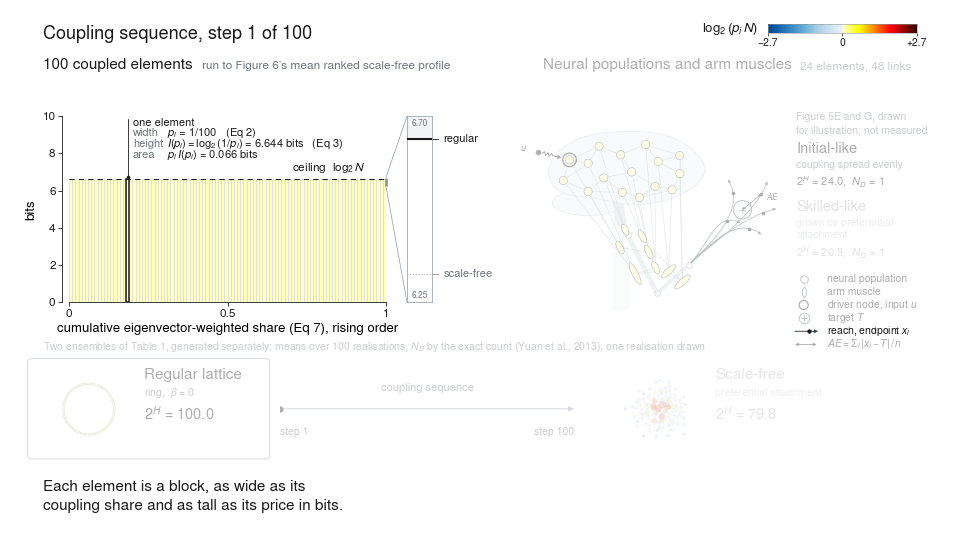

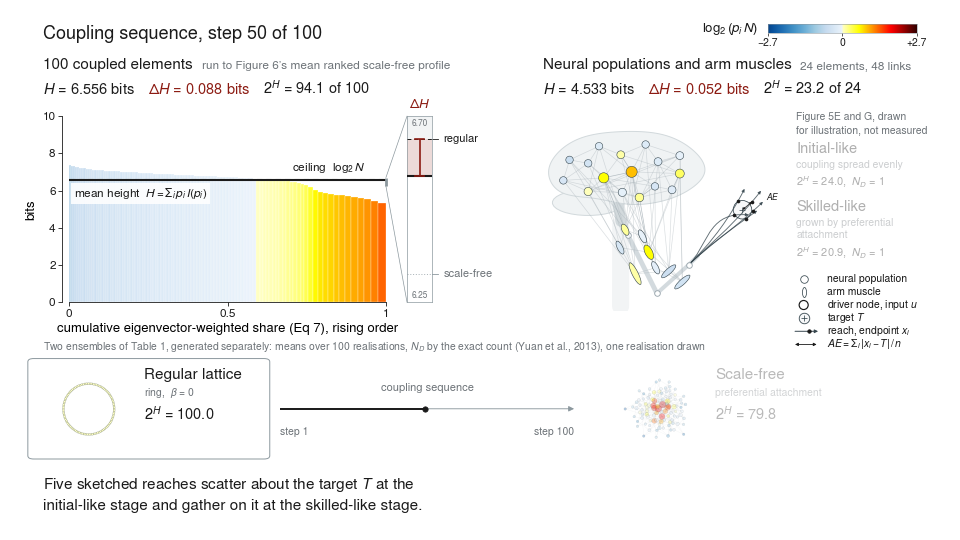

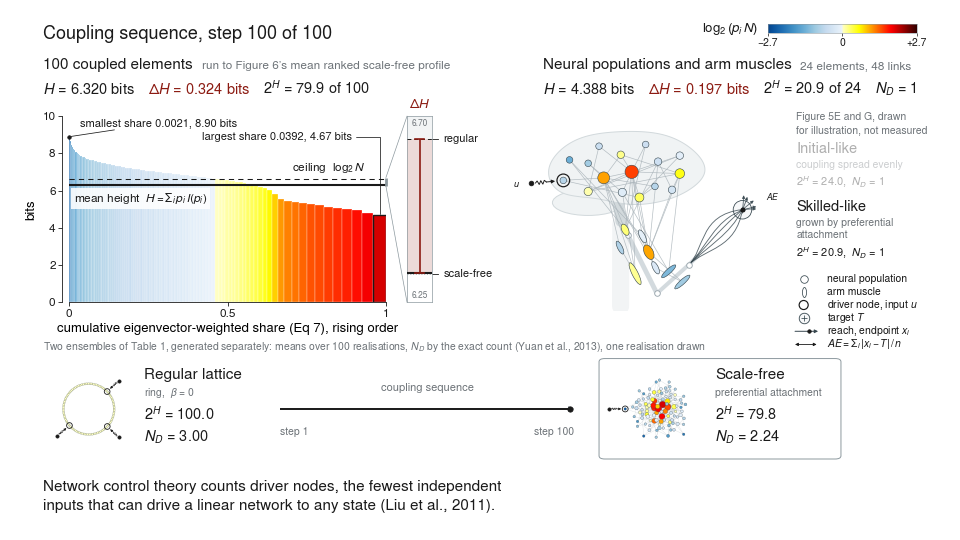

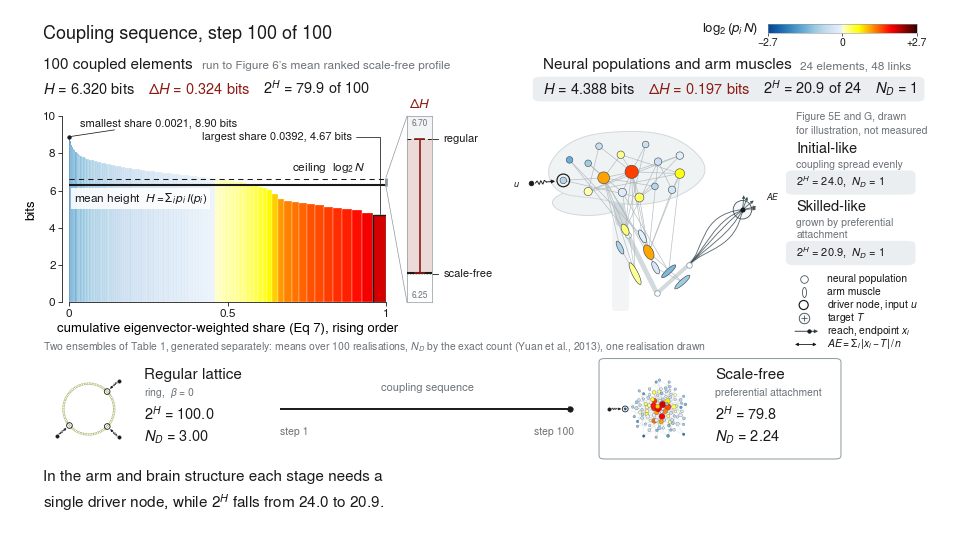

In [7]:
import io
from IPython.display import Image, display

PREVIEW = [13.0, 40.0, 72.0, 90.0]          # seconds into the video
fig = new_figure()
for s in PREVIEW:
    draw(fig, s)
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=DPI // 2, facecolor='white')
    display(Image(data=buf.getvalue(), width=960))

## Render

With `WRITE = True` the cell draws every frame and passes it to FFmpeg, which writes the video. `FIRST` and `LAST` limit the frames for a quick test. With `WRITE = False` nothing is written.

In [8]:
import shutil, subprocess, time
from pathlib import Path

WRITE = False                                # True draws every frame and writes the video
FIRST, LAST = 0, NFRAMES                     # a shorter range gives a quick test
OUT_DIR = Path(os.environ.get('MOVIE_OUT_DIR', '.'))
OUT = OUT_DIR / 'Supplementary_Video_1.mp4'


def ffmpeg_exe():
    exe = shutil.which('ffmpeg')
    if exe:
        return exe
    try:
        import imageio_ffmpeg
        return imageio_ffmpeg.get_ffmpeg_exe()
    except ImportError:
        raise RuntimeError('FFmpeg was not found. Put it on the path, or pip install imageio-ffmpeg.')


if WRITE:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    W_PX, H_PX = int(round(W_IN * DPI)), int(round(H_IN * DPI))
    cmd = [ffmpeg_exe(), '-y', '-v', 'error',
           '-f', 'rawvideo', '-pix_fmt', 'rgb24', '-video_size', f'{W_PX}x{H_PX}', '-framerate', str(FPS),
           '-i', '-',
           '-vf', 'scale=out_color_matrix=bt709:out_range=tv,format=yuv420p',
           '-c:v', 'libx264', '-preset', 'slow', '-crf', '18',
           '-colorspace', 'bt709', '-color_primaries', 'bt709', '-color_trc', 'bt709', '-color_range', 'tv',
           '-movflags', '+faststart',
           '-metadata', 'title=Supplementary Video 1. Control entropy along a coupling sequence', str(OUT)]
    enc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    fig = new_figure()
    t0 = time.time()
    for f in range(FIRST, LAST):
        draw(fig, f / FPS)
        fig.canvas.draw()
        enc.stdin.write(np.asarray(fig.canvas.buffer_rgba())[:, :, :3].tobytes())
        if (f - FIRST) % 300 == 0:
            print(f'frame {f} of {NFRAMES}   {time.time() - t0:6.0f} s')
    enc.stdin.close()
    enc.wait()
    print(f'wrote {OUT}   frames {FIRST} to {LAST - 1}   {(LAST - FIRST) / FPS:.1f} s of video   '
          f'{time.time() - t0:.0f} s to draw')
else:
    print(f'Nothing written. Set WRITE = True to draw {LAST - FIRST} frames and write {OUT}.')

Nothing written. Set WRITE = True to draw 3333 frames and write Supplementary_Video_1.mp4.


## Calculation. Every number the video shows

The values the video draws, for a check against Table 1 and Figures 5 and 6, and the time each caption stays fully on screen.

In [9]:
# ---------------------------------------------------------------------------
# Every number the video draws, for a check against Table 1 and Figures 5 and 6,
# and the time each caption stays fully on screen.
# ---------------------------------------------------------------------------
_D = MOVIE_DATA
print('Coupling sequence of Figure 6, N = 100')
for k in _D['KINDS']:
    print(f'  {k:<12} mean H {_D["HMEAN"][k]:.4f}   2^H {2 ** _D["HMEAN"][k]:6.1f}   '
          f'place on the run {_D["T_STAGE"][k]:.4f}')
_p1 = path(1.0); _I1 = np.log2(1 / _p1)
print(f'  step 100     H {Hf(_p1):.4f}   Delta H {CEIL - Hf(_p1):.4f}   2^H {2 ** Hf(_p1):.2f}   '
      f'prices {_I1.min():.2f} to {_I1.max():.2f} bits   shares {_p1.min():.4f} to {_p1.max():.4f}')
print('\nDriver nodes, mean of 100 realisations')
for k in K2:
    print(f'  {k:<12} exact {_D["ND_EXACT"][k]:.2f}   matching {_D["ND_MATCH"][k]:.2f}   '
          f'drawn set {_D["DRIVERS"][k]}')
print('\nArm and brain structure of Figure 5E and G')
for nm, S in _D['SCHEME'].items():
    print(f'  {nm:<8} H {S["H"]:.3f}   2^H {S["eff"]:.1f} of {len(S["nodes"])}   links {len(S["edges"])}   '
          f'N_D {S["nd"]}   driver {S["driver"]}')
print(f'\nVideo   {DURATION:.1f} s   {NFRAMES} frames at {FPS} a second   {int(W_IN * DPI)} by {int(H_IN * DPI)}')
print('Captions, seconds fully on screen and words a second')
for t0, t1, s in CAPS:
    words = len(re.sub(r'\$[^$]*\$', 'X', s).split())
    shown = t1 - t0 - 0.35
    print(f'  {STARTS[1] + t0:5.1f} to {STARTS[1] + t1:5.1f} s   {words:2d} words   {shown:4.1f} s   '
          f'{words / shown:.2f} a second')

Coupling sequence of Figure 6, N = 100
  regular      mean H 6.6439   2^H  100.0   place on the run 0.0000
  small-world  mean H 6.5832   2^H   95.9   place on the run 0.4118
  random       mean H 6.4820   2^H   89.4   place on the run 0.6934
  scalefree    mean H 6.3176   2^H   79.8   place on the run 1.0000
  step 100     H 6.3200   Delta H 0.3239   2^H 79.89   prices 4.67 to 8.90 bits   shares 0.0021 to 0.0392

Driver nodes, mean of 100 realisations
  regular      exact 3.00   matching 1.00   drawn set [0, 49, 74]
  scalefree    exact 2.24   matching 2.17   drawn set [72]

Arm and brain structure of Figure 5E and G
  initial  H 4.585   2^H 24.0 of 24   links 48   N_D 1   driver n11
  skilled  H 4.388   2^H 20.9 of 24   links 48   N_D 1   driver n12

Video   111.1 s   3333 frames at 30 a second   1920 by 1080
Captions, seconds fully on screen and words a second
    7.8 to  16.1 s   19 words    7.9 s   2.39 a second
   16.1 to  24.5 s   20 words    8.1 s   2.48 a second
   24.5 to  33